# Machine Learning Assignment 2
**Topics:** kNN, Logistic Regression, PCA  
**Total Marks:** 10

In [5]:
# ── Global imports ────────────────────────────────────────────────────────────
import os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score,
    mean_squared_error, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from PIL import Image

warnings.filterwarnings('ignore')
np.random.seed(42)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
print('All imports OK')

All imports OK


In [43]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## Q1 — k-Nearest Neighbours (kNN)

### 1a. Data Preprocessing

In [44]:
# ── Load & preprocess ─────────────────────────────────────────────────────────
file_path  = '/content/drive/MyDrive/ML/Ass2/Social_Network_Ads.xls'
df = pd.read_csv(file_path)   # adjust filename if needed
print('Shape:', df.shape)
print(df.head())
print('\nClass distribution:')
print(df['Purchased'].value_counts())

# Encode Gender
if 'Gender' in df.columns:
    df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

feature_cols = ['Gender', 'Age', 'EstimatedSalary']
X_raw = df[feature_cols].values
y     = df['Purchased'].values

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 90 / 10 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1, random_state=42, stratify=y
)
print(f'\nTrain: {X_train.shape}  Test: {X_test.shape}')

Shape: (400, 5)
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0

Class distribution:
Purchased
0    257
1    143
Name: count, dtype: int64

Train: (360, 3)  Test: (40, 3)


### 1b. 3-D Visualisation

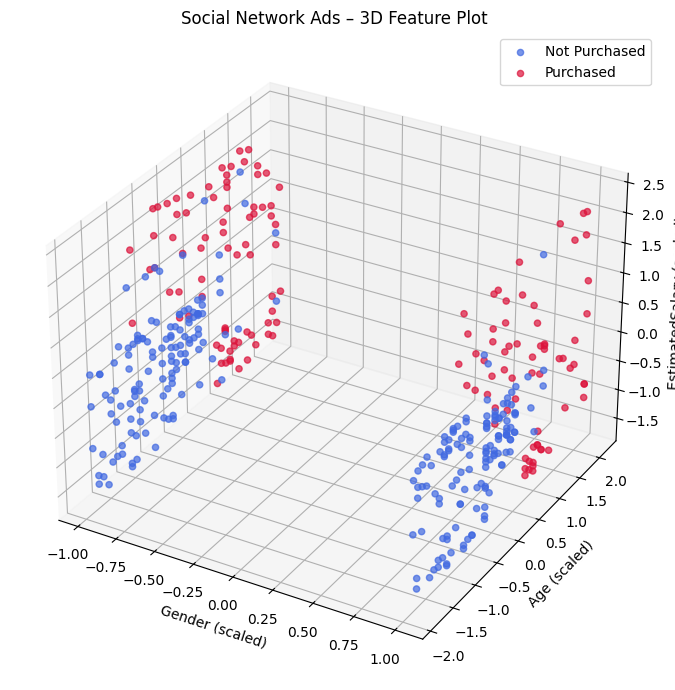

Figure saved.


In [7]:
fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection='3d')
for cls, col, lbl in zip([0, 1], ['royalblue', 'crimson'], ['Not Purchased', 'Purchased']):
    mask = y == cls
    ax.scatter(X_scaled[mask, 0], X_scaled[mask, 1], X_scaled[mask, 2],
               c=col, s=20, alpha=0.7, label=lbl)
ax.set_xlabel('Gender (scaled)')
ax.set_ylabel('Age (scaled)')
ax.set_zlabel('EstimatedSalary (scaled)')
ax.set_title('Social Network Ads – 3D Feature Plot')
ax.legend()
plt.tight_layout()
plt.savefig(FIG / 'q1_3d_scatter.png', dpi=200)
plt.show()
print('Figure saved.')

### 1c. kNN from Scratch + Helper Functions

In [8]:
# ── kNN from scratch (classification) ─────────────────────────────────────────
def knn_predict(Xtr, ytr, Xte, k=5, metric='euclidean'):
    """Scratch kNN classifier supporting euclidean / cosine / mahalanobis."""
    if metric == 'mahalanobis':
        cov     = np.cov(Xtr.T)
        cov_inv = np.linalg.pinv(cov)

    preds = []
    for x in Xte:
        if metric == 'euclidean':
            d = np.linalg.norm(Xtr - x, axis=1)
        elif metric == 'cosine':
            num = Xtr @ x
            den = np.linalg.norm(Xtr, axis=1) * (np.linalg.norm(x) + 1e-12)
            d   = 1.0 - (num / (den + 1e-12))
        elif metric == 'mahalanobis':
            diff = Xtr - x
            d    = np.sqrt(np.einsum('ij,jk,ik->i', diff, cov_inv, diff))
        else:
            raise ValueError(f'Unknown metric: {metric}')
        idx  = np.argsort(d)[:k]
        vals, counts = np.unique(ytr[idx], return_counts=True)
        preds.append(vals[np.argmax(counts)])
    return np.array(preds)


# ── kNN from scratch (regression) ─────────────────────────────────────────────
def knn_predict_regression(Xtr, ytr, Xte, k=5):
    """Scratch kNN regressor using Euclidean distance."""
    preds = []
    for x in Xte:
        d   = np.linalg.norm(Xtr - x, axis=1)
        idx = np.argsort(d)[:k]
        preds.append(np.mean(ytr[idx]))
    return np.array(preds)


# ── Metrics helper ─────────────────────────────────────────────────────────────
def compute_metrics(y_true, y_pred, verbose=False):
    m = {
        'accuracy' : accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall'   : recall_score(y_true, y_pred, zero_division=0),
        'f1'       : f1_score(y_true, y_pred, zero_division=0),
        'cm'       : confusion_matrix(y_true, y_pred),
    }
    if verbose:
        for k, v in m.items():
            if k != 'cm':
                print(f'  {k:10s}: {v:.4f}')
        print(f'  confusion_matrix:\n{m["cm"]}')
    return m

print('Scratch implementations defined.')

Scratch implementations defined.


### 1d. Scratch vs Library Comparison (k = 5)

=== Scratch kNN (k=5) ===
  accuracy  : 0.9250
  precision : 0.9231
  recall    : 0.8571
  f1        : 0.8889
  confusion_matrix:
[[25  1]
 [ 2 12]]

=== sklearn kNN (k=5) ===
  accuracy  : 0.9250
  precision : 0.9231
  recall    : 0.8571
  f1        : 0.8889
  confusion_matrix:
[[25  1]
 [ 2 12]]


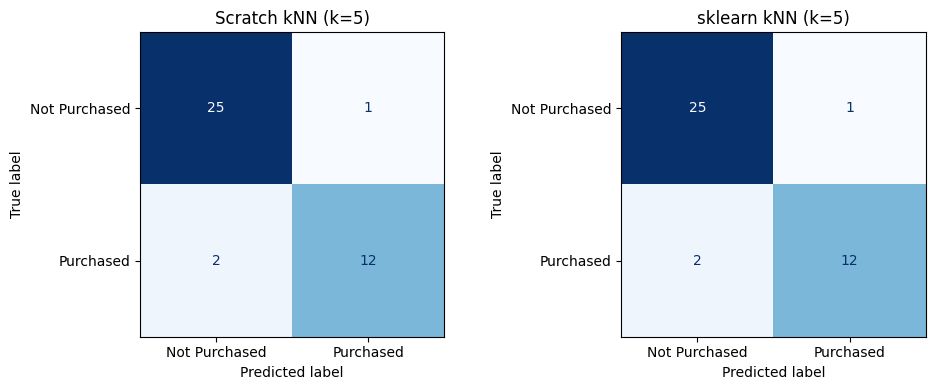

In [9]:
# Scratch kNN k=5
y_scratch = knn_predict(X_train, y_train, X_test, k=5, metric='euclidean')

# sklearn kNN k=5
knn_lib = KNeighborsClassifier(n_neighbors=5)
knn_lib.fit(X_train, y_train)
y_lib = knn_lib.predict(X_test)

print('=== Scratch kNN (k=5) ===')
m_scratch = compute_metrics(y_test, y_scratch, verbose=True)

print('\n=== sklearn kNN (k=5) ===')
m_lib = compute_metrics(y_test, y_lib, verbose=True)

# Visualise confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cm, title in zip(axes,
                         [m_scratch['cm'], m_lib['cm']],
                         ['Scratch kNN (k=5)', 'sklearn kNN (k=5)']):
    disp = ConfusionMatrixDisplay(cm, display_labels=['Not Purchased', 'Purchased'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG / 'q1_confusion_scratch_vs_lib.png', dpi=200)
plt.show()

### 1e. Metrics Across k (k = 1 … 25)

    Accuracy  Precision  Recall      F1
k                                      
1      0.875     0.9091  0.7143  0.8000
2      0.800     0.8750  0.5000  0.6364
3      0.925     0.9231  0.8571  0.8889
4      0.925     0.9231  0.8571  0.8889
5      0.925     0.9231  0.8571  0.8889
6      0.925     0.9231  0.8571  0.8889
7      0.925     0.9231  0.8571  0.8889
8      0.925     0.9231  0.8571  0.8889
9      0.925     0.9231  0.8571  0.8889
10     0.925     0.9231  0.8571  0.8889
11     0.925     0.9231  0.8571  0.8889
12     0.925     0.9231  0.8571  0.8889
13     0.925     0.9231  0.8571  0.8889
14     0.925     0.9231  0.8571  0.8889
15     0.925     0.9231  0.8571  0.8889
16     0.925     0.9231  0.8571  0.8889
17     0.925     0.9231  0.8571  0.8889
18     0.925     0.9231  0.8571  0.8889
19     0.925     0.9231  0.8571  0.8889
20     0.925     0.9231  0.8571  0.8889
21     0.925     0.9231  0.8571  0.8889
22     0.925     0.9231  0.8571  0.8889
23     0.925     0.9231  0.8571  0.8889


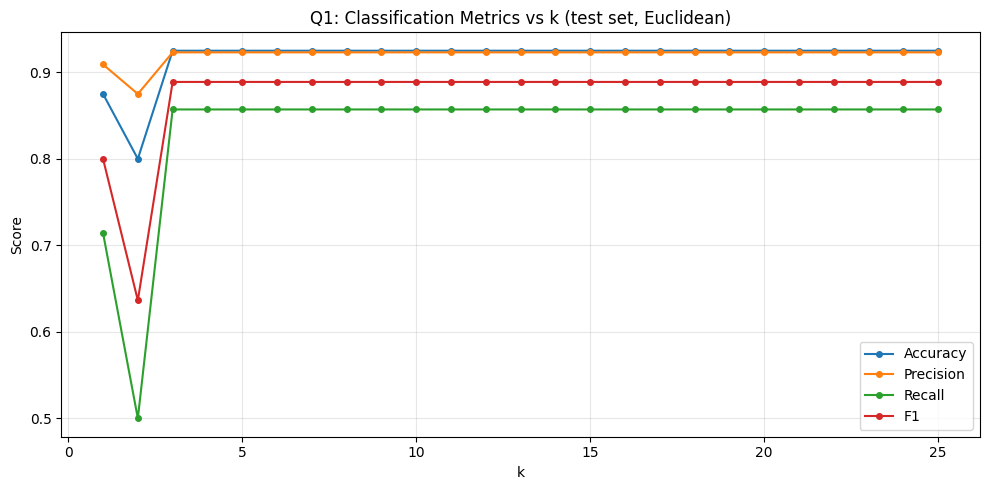

In [10]:
k_values = list(range(1, 26))
metrics_k = {}
for k in k_values:
    yp = knn_predict(X_train, y_train, X_test, k=k, metric='euclidean')
    metrics_k[k] = compute_metrics(y_test, yp)

# Table
rows = []
for k in k_values:
    m = metrics_k[k]
    rows.append({'k': k, 'Accuracy': round(m['accuracy'],4),
                 'Precision': round(m['precision'],4),
                 'Recall': round(m['recall'],4),
                 'F1': round(m['f1'],4)})
df_metrics = pd.DataFrame(rows).set_index('k')
print(df_metrics.to_string())

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
for col in df_metrics.columns:
    ax.plot(k_values, df_metrics[col], marker='o', ms=4, label=col)
ax.set_xlabel('k')
ax.set_ylabel('Score')
ax.set_title('Q1: Classification Metrics vs k (test set, Euclidean)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q1_metrics_vs_k.png', dpi=200)
plt.show()

### 1f. 5-Fold Stratified Cross-Validation

Best k (5-fold stratified CV) = 5  |  CV accuracy = 0.9200


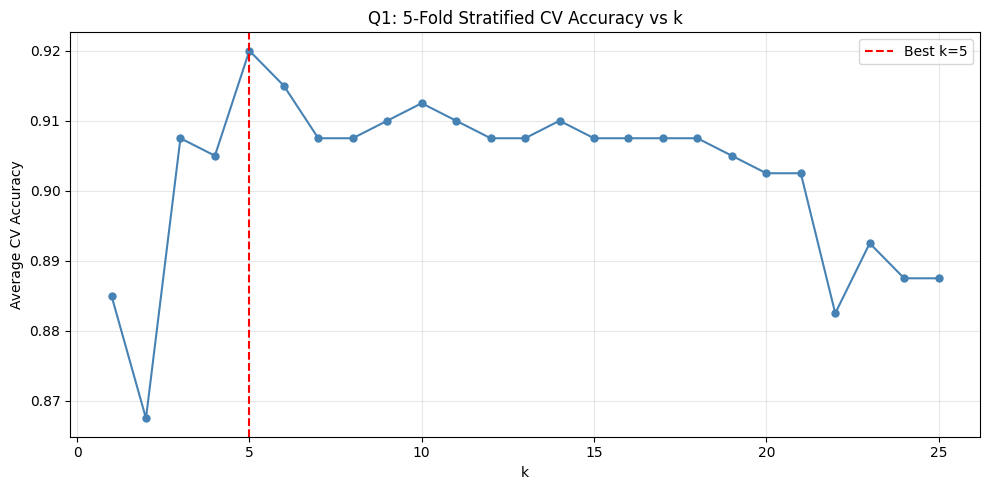

In [11]:
# StratifiedKFold is correct for classification (preserves class ratios in each fold)
skf    = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = []

for k in k_values:
    fold_accs = []
    for tr_idx, val_idx in skf.split(X_scaled, y):
        Xtr_, Xval_ = X_scaled[tr_idx], X_scaled[val_idx]
        ytr_, yval_ = y[tr_idx],         y[val_idx]
        yh = knn_predict(Xtr_, ytr_, Xval_, k=k, metric='euclidean')
        fold_accs.append(accuracy_score(yval_, yh))
    cv_acc.append(np.mean(fold_accs))

best_k = k_values[int(np.argmax(cv_acc))]
print(f'Best k (5-fold stratified CV) = {best_k}  |  CV accuracy = {max(cv_acc):.4f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_values, cv_acc, marker='o', color='steelblue', ms=5)
ax.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
ax.set_xlabel('k')
ax.set_ylabel('Average CV Accuracy')
ax.set_title('Q1: 5-Fold Stratified CV Accuracy vs k')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q1_cv_accuracy.png', dpi=200)
plt.show()

### 1g. Distance Metric Comparison (best k)

Distance metric comparison at best k=5:
Metric              Acc    Prec  Recall      F1
--------------------------------------------------
euclidean        0.9250  0.9231  0.8571  0.8889
cosine           0.9250  0.9231  0.8571  0.8889
mahalanobis      0.9250  0.9231  0.8571  0.8889

Best metric by F1: euclidean


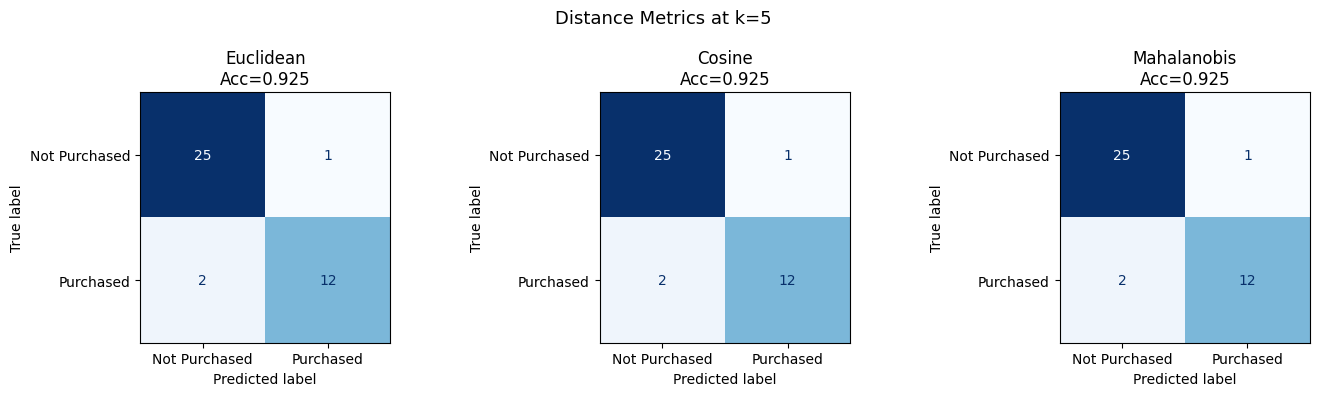

In [12]:
metrics_dist = {}
for metric in ['euclidean', 'cosine', 'mahalanobis']:
    yp = knn_predict(X_train, y_train, X_test, k=best_k, metric=metric)
    metrics_dist[metric] = compute_metrics(y_test, yp)

print(f'Distance metric comparison at best k={best_k}:')
print(f'{"Metric":<15} {"Acc":>7} {"Prec":>7} {"Recall":>7} {"F1":>7}')
print('-' * 50)
for m_name, m_val in metrics_dist.items():
    print(f'{m_name:<15} {m_val["accuracy"]:7.4f} {m_val["precision"]:7.4f} '
          f'{m_val["recall"]:7.4f} {m_val["f1"]:7.4f}')

best_metric = max(metrics_dist, key=lambda m: metrics_dist[m]['f1'])
print(f'\nBest metric by F1: {best_metric}')

# Confusion matrices for each metric
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (m_name, m_val) in zip(axes, metrics_dist.items()):
    disp = ConfusionMatrixDisplay(m_val['cm'],
                                   display_labels=['Not Purchased', 'Purchased'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{m_name.capitalize()}\nAcc={m_val["accuracy"]:.3f}')
plt.suptitle(f'Distance Metrics at k={best_k}', fontsize=13)
plt.tight_layout()
plt.savefig(FIG / 'q1_distance_metrics_cm.png', dpi=200)
plt.show()

### 1h. Effect of Extreme k Values & Inference

In [13]:
extreme_ks = [1, best_k, len(X_train)]
extreme_results = {}
for k in extreme_ks:
    yp = knn_predict(X_train, y_train, X_test, k=k, metric='euclidean')
    extreme_results[k] = compute_metrics(y_test, yp)
    print(f'k={k:>4}: acc={extreme_results[k]["accuracy"]:.4f}  '
          f'f1={extreme_results[k]["f1"]:.4f}')

print("""
Inference:
  k=1   : The model memorises training data exactly — zero training error but very high
           variance. Each test point is classified by its single nearest neighbour, making
           predictions sensitive to noise and outliers (overfitting / low bias, high variance).

  k=optimal: Balances bias and variance. The neighbourhood is large enough to smooth out
           noise yet small enough to capture local structure.

  k=N   : Every training sample votes, so every test point is assigned the majority class
           regardless of its location in feature space. This is maximum bias (underfitting).
           Accuracy collapses toward the prior probability of the majority class.
""")

k=   1: acc=0.8750  f1=0.8000
k=   5: acc=0.9250  f1=0.8889
k= 360: acc=0.6500  f1=0.0000

Inference:
  k=1   : The model memorises training data exactly — zero training error but very high
           variance. Each test point is classified by its single nearest neighbour, making
           predictions sensitive to noise and outliers (overfitting / low bias, high variance).

  k=optimal: Balances bias and variance. The neighbourhood is large enough to smooth out
           noise yet small enough to capture local structure.

  k=N   : Every training sample votes, so every test point is assigned the majority class
           regardless of its location in feature space. This is maximum bias (underfitting).
           Accuracy collapses toward the prior probability of the majority class.



### 1i. Effect of Training Set Size (fixed best k)

In [14]:
train_fracs = [0.40, 0.60, 0.90]
size_results = {}
print(f'Fixed k={best_k}, varying training size:')
print(f'{"Train %":<10} {"Acc":>7} {"F1":>7}')
for frac in train_fracs:
    Xtr_, Xte_, ytr_, yte_ = train_test_split(
        X_scaled, y, train_size=frac, random_state=42, stratify=y)
    yp = knn_predict(Xtr_, ytr_, Xte_, k=best_k, metric='euclidean')
    size_results[frac] = compute_metrics(yte_, yp)
    print(f'{int(frac*100):>6}%    {size_results[frac]["accuracy"]:7.4f} '
          f'{size_results[frac]["f1"]:7.4f}')

print("""
Observation:
  As training data decreases, accuracy drops — particularly at 40%. kNN is a
  non-parametric model; its quality is directly tied to the density and
  representativeness of training samples. With fewer points the neighbourhood
  becomes less reliable, and the optimal k found at 90% may no longer be
  optimal for smaller sets (sparser data needs smaller k).
""")

Fixed k=5, varying training size:
Train %        Acc      F1
    40%     0.8875  0.8402
    60%     0.9187  0.8908
    90%     0.9250  0.8889

Observation:
  As training data decreases, accuracy drops — particularly at 40%. kNN is a
  non-parametric model; its quality is directly tied to the density and
  representativeness of training samples. With fewer points the neighbourhood
  becomes less reliable, and the optimal k found at 90% may no longer be
  optimal for smaller sets (sparser data needs smaller k).



### 1j. Decision Boundary Visualisation (all feature pairs, k ∈ {1, best_k, 15})

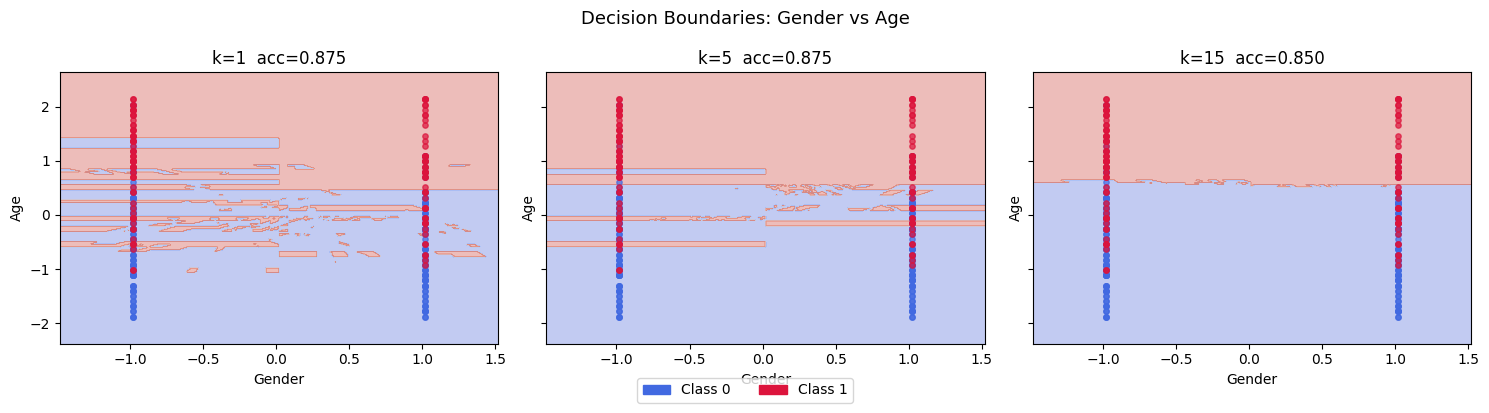

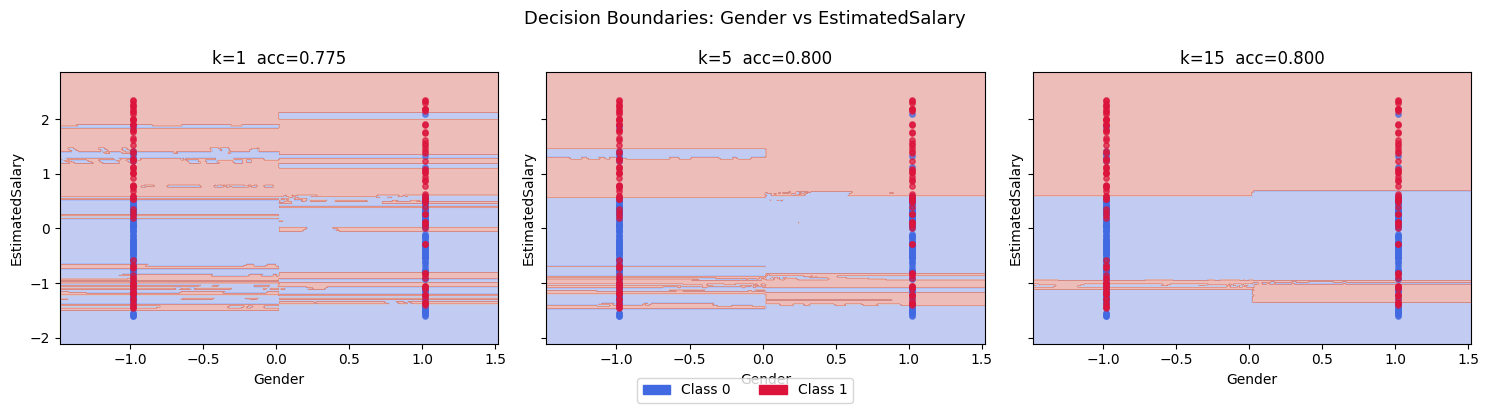

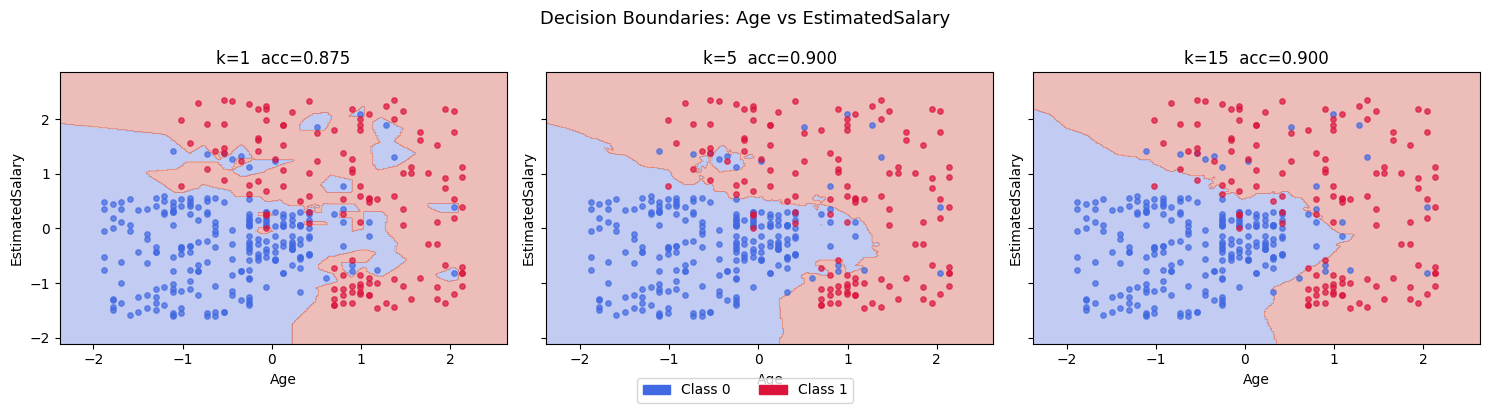


Comment on smoothness:
  k=1  produces highly irregular, jagged boundaries — each training point
       creates its own Voronoi cell (maximum overfitting).
  k=best_k balances smoothness with class separation.
  k=15 (larger) yields visibly smoother, more regular boundaries because
       the vote is spread over more neighbours, averaging out local noise.
  In general, larger k ⟹ smoother boundary ⟹ higher bias but lower variance.



In [15]:
feature_pairs = [(0, 1, 'Gender', 'Age'),
                 (0, 2, 'Gender', 'EstimatedSalary'),
                 (1, 2, 'Age',    'EstimatedSalary')]
ks_boundary   = sorted({1, best_k, 15})

for (fi, fj, fn_i, fn_j) in feature_pairs:
    X2 = X_scaled[:, [fi, fj]]
    Xtr2, Xte2, ytr2, yte2 = train_test_split(
        X2, y, test_size=0.1, random_state=42, stratify=y)

    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(1, len(ks_boundary), figsize=(5 * len(ks_boundary), 4),
                             sharey=True)
    for ax, k in zip(axes, ks_boundary):
        Z = knn_predict(Xtr2, ytr2, grid, k=k, metric='euclidean').reshape(xx.shape)
        ax.contourf(xx, yy, Z, alpha=0.35, cmap='coolwarm')
        for cls, col in zip([0, 1], ['royalblue', 'crimson']):
            m = ytr2 == cls
            ax.scatter(Xtr2[m, 0], Xtr2[m, 1], c=col, s=15, alpha=0.7)
        ax.set_title(f'k={k}  acc={accuracy_score(yte2, knn_predict(Xtr2,ytr2,Xte2,k=k)):.3f}')
        ax.set_xlabel(fn_i)
        ax.set_ylabel(fn_j)

    p0 = mpatches.Patch(color='royalblue', label='Class 0')
    p1 = mpatches.Patch(color='crimson',   label='Class 1')
    fig.legend(handles=[p0, p1], loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02))
    plt.suptitle(f'Decision Boundaries: {fn_i} vs {fn_j}', fontsize=13)
    plt.tight_layout()
    fname = FIG / f'q1_boundary_{fn_i}_{fn_j}.png'
    plt.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

print("""
Comment on smoothness:
  k=1  produces highly irregular, jagged boundaries — each training point
       creates its own Voronoi cell (maximum overfitting).
  k=best_k balances smoothness with class separation.
  k=15 (larger) yields visibly smoother, more regular boundaries because
       the vote is spread over more neighbours, averaging out local noise.
  In general, larger k ⟹ smoother boundary ⟹ higher bias but lower variance.
""")

### 1k. kNN Regression (from scratch + sklearn, 60:40 split)

Best k for regression (MSE): 19  MSE=1.00524


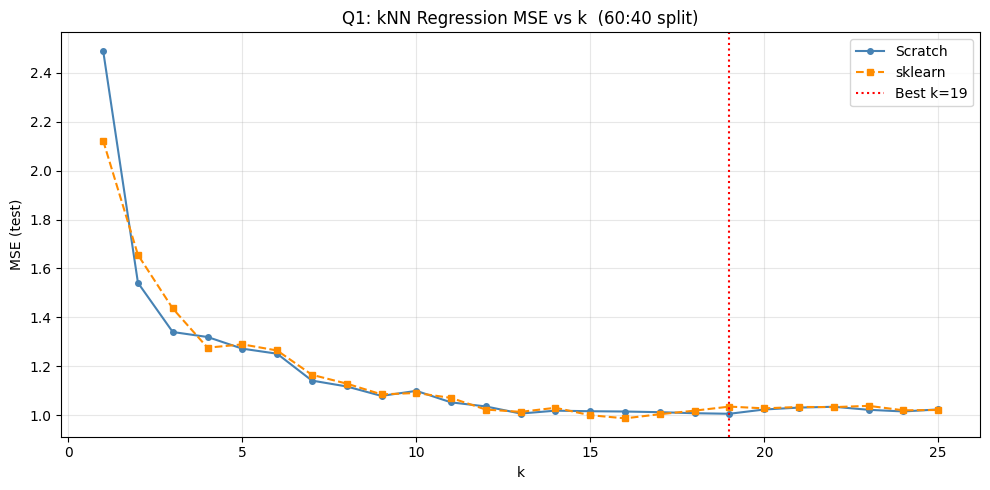


MSE table:
    MSE_scratch  MSE_sklearn
k                           
1       2.49059      2.12246
2       1.54108      1.65526
3       1.33978      1.43600
4       1.31931      1.27552
5       1.27160      1.28923
6       1.25093      1.26412
7       1.14102      1.16471
8       1.11693      1.12859
9       1.07834      1.08458
10      1.09900      1.09023
11      1.05188      1.07014
12      1.03517      1.02234
13      1.00614      1.01313
14      1.01799      1.02975
15      1.01560      0.99933
16      1.01445      0.98654
17      1.01174      1.00351
18      1.00747      1.01803
19      1.00524      1.03459
20      1.02277      1.02739
21      1.03057      1.03318
22      1.03391      1.03250
23      1.02145      1.03764
24      1.01471      1.01939
25      1.02305      1.02070


In [16]:
# Inputs: Gender, Age  |  Output: EstimatedSalary  (all in scaled space)
X_reg  = X_scaled[:, :2]
y_reg  = X_scaled[:, 2]

Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(
    X_reg, y_reg, test_size=0.4, random_state=42)

mse_scratch = {}
mse_sklearn = {}
for k in k_values:
    # from scratch
    yh_s = knn_predict_regression(Xtr_r, ytr_r, Xte_r, k=k)
    mse_scratch[k] = mean_squared_error(yte_r, yh_s)
    # sklearn
    kr = KNeighborsRegressor(n_neighbors=k)
    kr.fit(Xtr_r, ytr_r)
    mse_sklearn[k] = mean_squared_error(yte_r, kr.predict(Xte_r))

best_k_reg = min(mse_scratch, key=mse_scratch.get)
print(f'Best k for regression (MSE): {best_k_reg}  '
      f'MSE={mse_scratch[best_k_reg]:.5f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_values, list(mse_scratch.values()), marker='o', ms=4,
        label='Scratch', color='steelblue')
ax.plot(k_values, list(mse_sklearn.values()), marker='s', ms=4,
        label='sklearn', color='darkorange', linestyle='--')
ax.axvline(best_k_reg, color='red', linestyle=':', label=f'Best k={best_k_reg}')
ax.set_xlabel('k')
ax.set_ylabel('MSE (test)')
ax.set_title('Q1: kNN Regression MSE vs k  (60:40 split)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q1_knn_regression_mse.png', dpi=200)
plt.show()

print('\nMSE table:')
mse_df = pd.DataFrame({'k': k_values,
                        'MSE_scratch': [mse_scratch[k] for k in k_values],
                        'MSE_sklearn': [mse_sklearn[k] for k in k_values]}).set_index('k')
print(mse_df.round(5).to_string())

---
## Q2 — Logistic Regression (Binary Classification)

### 2a. Sigmoid & Implementations

In [17]:
# Add bias column
X_tr2 = np.hstack([np.ones((len(X_train), 1)), X_train])
X_te2 = np.hstack([np.ones((len(X_test),  1)), X_test])

def sigmoid(z):
    """Numerically stable sigmoid."""
    return np.where(z >= 0,
                    1 / (1 + np.exp(-z)),
                    np.exp(z) / (1 + np.exp(z)))


# ── SGD ────────────────────────────────────────────────────────────────────────
def logistic_sgd(X, y, lr=0.1, epochs=2000, tol=1e-6):
    """
    Stochastic Gradient Descent for logistic regression.
    Returns weights and per-epoch loss list.
    """
    w      = np.zeros(X.shape[1])
    losses = []
    for epoch in range(epochs):
        idx = np.random.permutation(len(X))
        for i in idx:
            xi  = X[i]
            yi  = y[i]
            p   = sigmoid(xi @ w)
            w  -= lr * (p - yi) * xi
        # compute full-dataset log-loss for tracking
        p_all = sigmoid(X @ w)
        p_all = np.clip(p_all, 1e-12, 1 - 1e-12)
        loss  = -np.mean(y * np.log(p_all) + (1 - y) * np.log(1 - p_all))
        losses.append(loss)
        if epoch > 0 and abs(losses[-2] - losses[-1]) < tol:
            print(f'  SGD converged at epoch {epoch}')
            break
    return w, losses


# ── Newton / IRLS ──────────────────────────────────────────────────────────────
def logistic_newton(X, y, max_iter=50, tol=1e-6):
    """
    Newton's method (IRLS) for logistic regression.
    Returns weights, iteration count, and per-iteration loss list.
    """
    w      = np.zeros(X.shape[1])
    losses = []
    n_iter = 0
    for i in range(max_iter):
        p       = sigmoid(X @ w)
        p_clip  = np.clip(p, 1e-10, 1 - 1e-10)
        loss    = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
        losses.append(loss)
        diag    = p * (1 - p)                     # IRLS weight vector
        H       = X.T @ (diag[:, None] * X)       # Hessian  (D×D)
        grad    = X.T @ (p - y)                   # gradient (D,)
        step    = np.linalg.solve(H + 1e-8 * np.eye(H.shape[0]), grad)
        w      -= step
        n_iter += 1
        if np.linalg.norm(step) < tol:
            print(f'  Newton/IRLS converged at iteration {n_iter}')
            break
    return w, n_iter, losses


# Train
print('Training SGD ...')
w_sgd, sgd_losses = logistic_sgd(X_tr2, y_train, lr=0.1, epochs=2000)

print('Training Newton/IRLS ...')
w_newton, newton_iters, newton_losses = logistic_newton(X_tr2, y_train, max_iter=100)

print('Training sklearn LogisticRegression ...')
log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_train, y_train)

print('\nDone.')

Training SGD ...
  SGD converged at epoch 760
Training Newton/IRLS ...
  Newton/IRLS converged at iteration 7
Training sklearn LogisticRegression ...

Done.


### 2b. Convergence Comparison — SGD vs Newton/IRLS

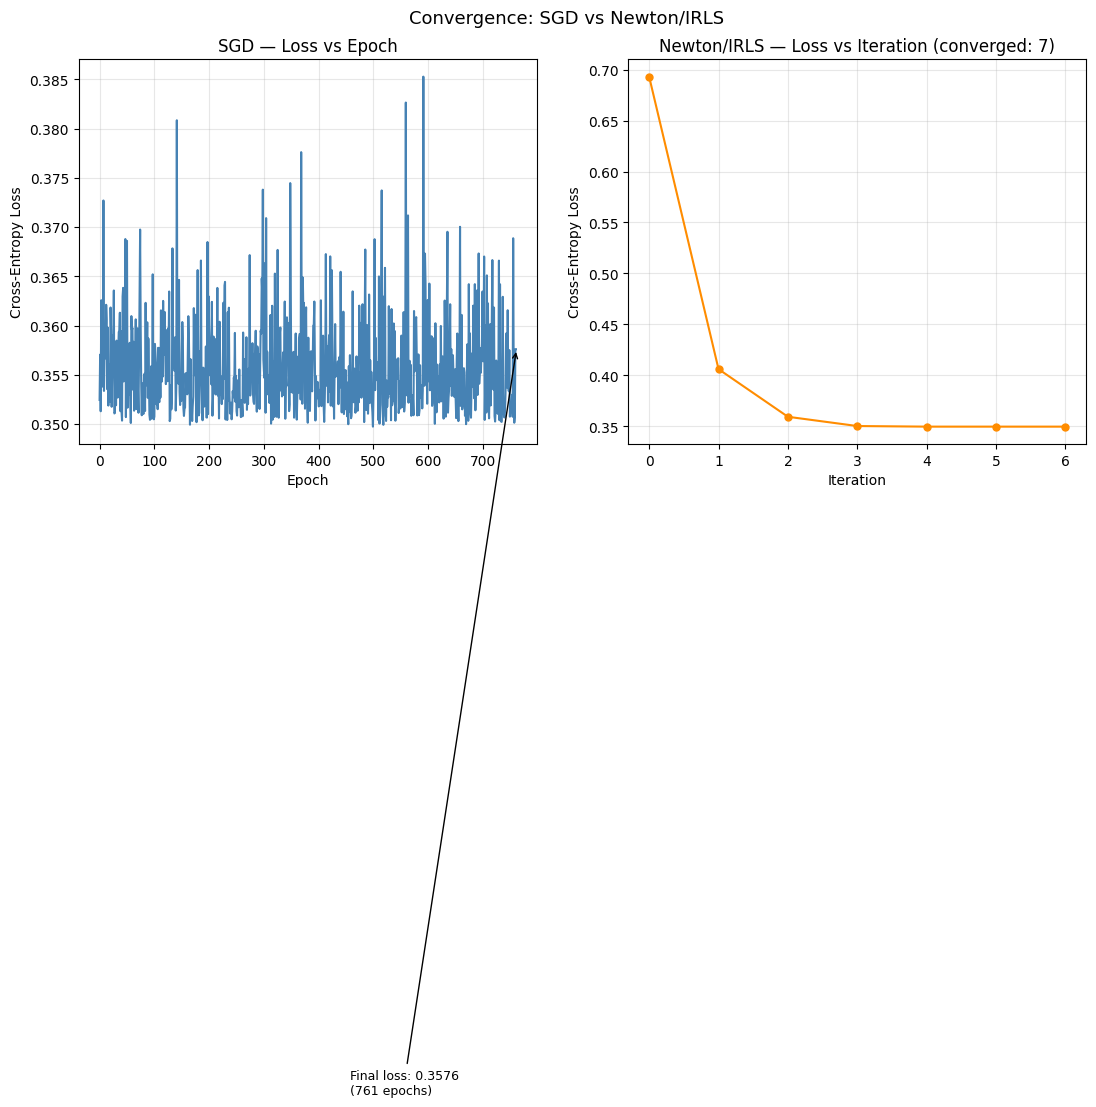


Convergence comparison:
  SGD       converged after ~761 epochs (one weight update per sample).
  Newton/IRLS converged after 7 iterations.

  Newton's method uses second-order information (Hessian / curvature) to
  choose step sizes, allowing much faster convergence per iteration.
  However, each Newton step costs O(D^3) to invert the Hessian, whereas
  each SGD epoch costs O(N·D). For small D (as here), Newton is far faster.



In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(sgd_losses, color='steelblue')
axes[0].set_title('SGD — Loss vs Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, alpha=0.3)
axes[0].annotate(f'Final loss: {sgd_losses[-1]:.4f}\n({len(sgd_losses)} epochs)',
                 xy=(len(sgd_losses), sgd_losses[-1]),
                 xytext=(len(sgd_losses)*0.6, sgd_losses[0]*0.8),
                 arrowprops=dict(arrowstyle='->', color='black'), fontsize=9)

axes[1].plot(newton_losses, color='darkorange', marker='o', ms=5)
axes[1].set_title(f'Newton/IRLS — Loss vs Iteration (converged: {newton_iters})')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Cross-Entropy Loss')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Convergence: SGD vs Newton/IRLS', fontsize=13)
plt.tight_layout()
plt.savefig(FIG / 'q2_convergence.png', dpi=200)
plt.show()

print(f"""
Convergence comparison:
  SGD       converged after ~{len(sgd_losses)} epochs (one weight update per sample).
  Newton/IRLS converged after {newton_iters} iterations.

  Newton's method uses second-order information (Hessian / curvature) to
  choose step sizes, allowing much faster convergence per iteration.
  However, each Newton step costs O(D^3) to invert the Hessian, whereas
  each SGD epoch costs O(N·D). For small D (as here), Newton is far faster.
""")

### 2c. Performance Comparison (90/10 split)

=== SGD ===
  accuracy  : 0.8000
  precision : 0.8750
  recall    : 0.5000
  f1        : 0.6364
  confusion_matrix:
[[25  1]
 [ 7  7]]

=== Newton/IRLS ===
  accuracy  : 0.8750
  precision : 0.9091
  recall    : 0.7143
  f1        : 0.8000
  confusion_matrix:
[[25  1]
 [ 4 10]]

=== sklearn ===
  accuracy  : 0.8500
  precision : 0.9000
  recall    : 0.6429
  f1        : 0.7500
  confusion_matrix:
[[25  1]
 [ 5  9]]


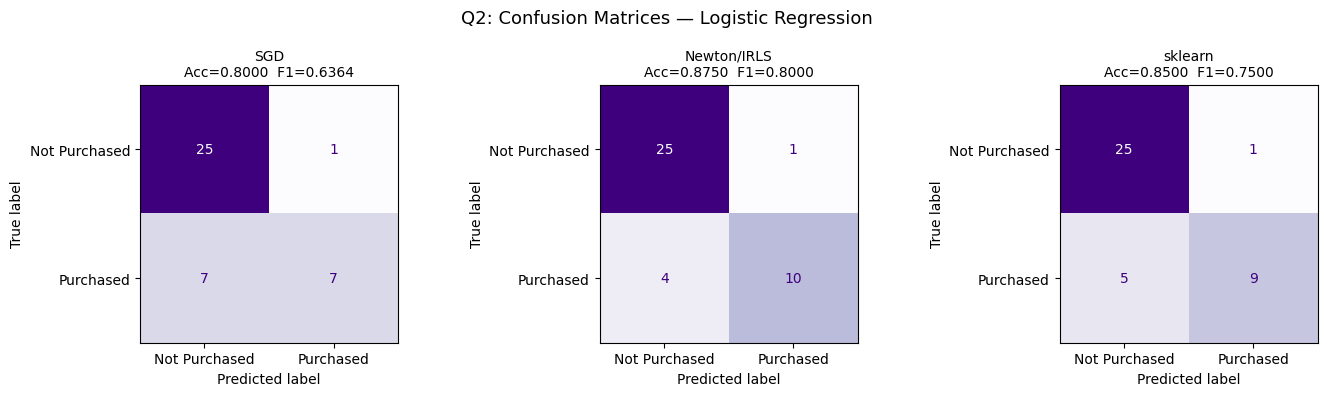

In [19]:
pred_sgd    = (sigmoid(X_te2 @ w_sgd)    >= 0.5).astype(int)
pred_newton = (sigmoid(X_te2 @ w_newton) >= 0.5).astype(int)
pred_lib    = log_reg.predict(X_test)

print('=== SGD ===')
m_sgd = compute_metrics(y_test, pred_sgd, verbose=True)
print('\n=== Newton/IRLS ===')
m_newton = compute_metrics(y_test, pred_newton, verbose=True)
print('\n=== sklearn ===')
m_lib_q2 = compute_metrics(y_test, pred_lib, verbose=True)

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
methods = [('SGD', m_sgd), ('Newton/IRLS', m_newton), ('sklearn', m_lib_q2)]
for ax, (title, m_val) in zip(axes, methods):
    ConfusionMatrixDisplay(m_val['cm'],
                           display_labels=['Not Purchased', 'Purchased']).plot(
        ax=ax, colorbar=False, cmap='Purples')
    ax.set_title(f'{title}\nAcc={m_val["accuracy"]:.4f}  F1={m_val["f1"]:.4f}',
                 fontsize=10)
plt.suptitle('Q2: Confusion Matrices — Logistic Regression', fontsize=13)
plt.tight_layout()
plt.savefig(FIG / 'q2_confusion_all.png', dpi=200)
plt.show()

### 2d. Decision Boundary Visualisation (2D projection + 3D)

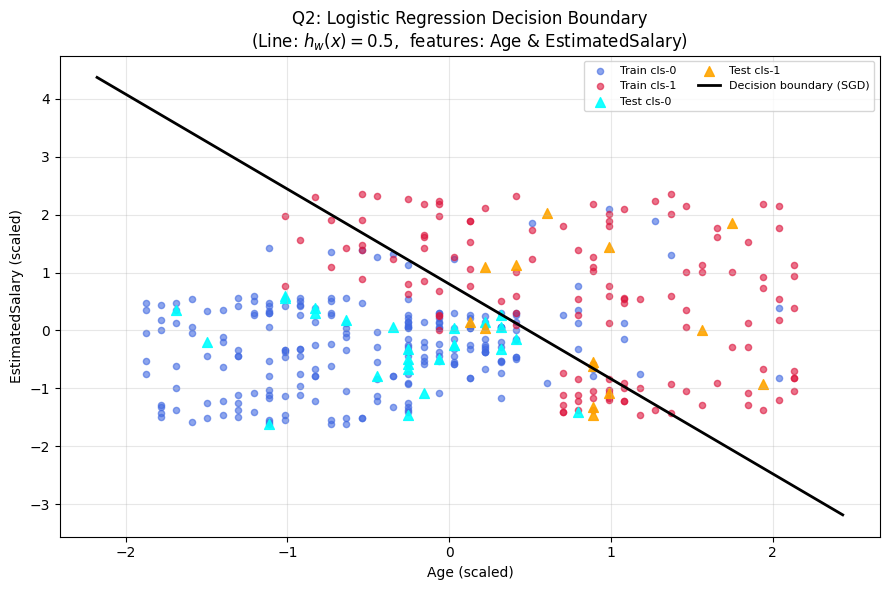

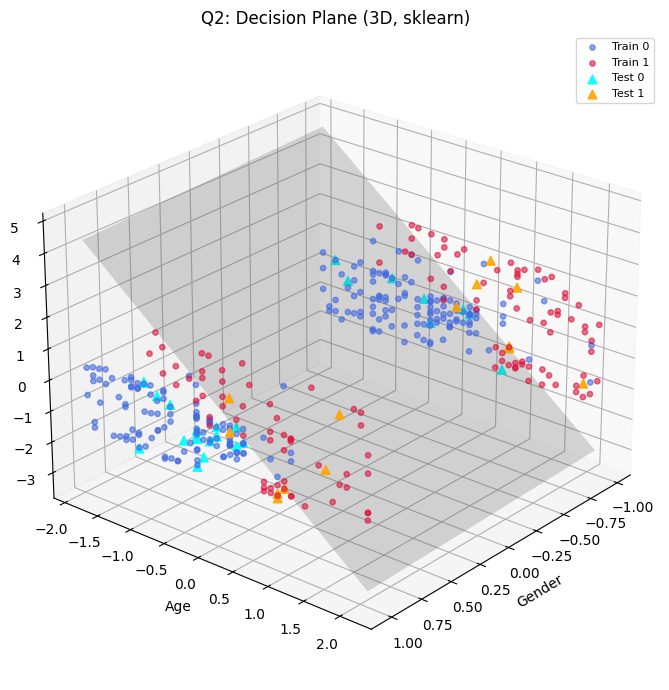

In [20]:
# ── 2-D decision boundary (Age vs EstimatedSalary) — matches assignment spec ──
# The assignment asks for a straight-line boundary h_w(x) = 0.5  in 2-D
# We project onto the two most discriminative features: Age & EstimatedSalary

X2d     = X_scaled[:, 1:3]   # Age, EstimatedSalary
X2d_tr  = np.hstack([np.ones((len(X_train), 1)), X_train[:, 1:3]])
X2d_te  = np.hstack([np.ones((len(X_test),  1)), X_test[:,  1:3]])

w2d, _   = logistic_sgd(X2d_tr, y_train, lr=0.1, epochs=2000)
log2d    = LogisticRegression(max_iter=2000).fit(X_train[:, 1:3], y_train)

# Boundary line: w0 + w1*x1 + w2*x2 = 0  =>  x2 = -(w0 + w1*x1)/w2
x1_line = np.linspace(X2d[:, 0].min() - 0.3, X2d[:, 0].max() + 0.3, 200)
if abs(w2d[2]) > 1e-6:
    x2_line = -(w2d[0] + w2d[1] * x1_line) / w2d[2]

fig, ax = plt.subplots(figsize=(9, 6))

# Training data
for cls, col, mk, lbl in zip([0,1], ['royalblue','crimson'], ['o','o'],
                              ['Train cls-0','Train cls-1']):
    m = y_train == cls
    ax.scatter(X_train[m, 1], X_train[m, 2], c=col, s=20, alpha=0.6, label=lbl)

# Test data
for cls, col, mk, lbl in zip([0,1], ['cyan','orange'], ['^','^'],
                              ['Test cls-0','Test cls-1']):
    m = y_test == cls
    ax.scatter(X_test[m, 1], X_test[m, 2], c=col, s=50, marker='^', alpha=0.9, label=lbl)

# Decision boundary
ax.plot(x1_line, x2_line, 'k-', linewidth=2, label='Decision boundary (SGD)')

ax.set_xlabel('Age (scaled)')
ax.set_ylabel('EstimatedSalary (scaled)')
ax.set_title('Q2: Logistic Regression Decision Boundary\n'
             r'(Line: $h_w(x)=0.5$,  features: Age & EstimatedSalary)')
ax.legend(fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q2_logreg_boundary_2d.png', dpi=200)
plt.show()

# ── 3D boundary plane (all 3 features) ────────────────────────────────────────
fig = plt.figure(figsize=(10, 7))
ax3 = fig.add_subplot(111, projection='3d')
for cls, col, lbl in zip([0,1],['royalblue','crimson'],['Train 0','Train 1']):
    m = y_train == cls
    ax3.scatter(X_train[m,0], X_train[m,1], X_train[m,2], c=col, s=15, alpha=0.6, label=lbl)
for cls, col, lbl in zip([0,1],['cyan','orange'],['Test 0','Test 1']):
    m = y_test == cls
    ax3.scatter(X_test[m,0], X_test[m,1], X_test[m,2], c=col, s=40,
                marker='^', alpha=0.9, label=lbl)

w3 = np.hstack([log_reg.intercept_, log_reg.coef_.flatten()])
x1v = np.linspace(X_train[:,0].min(), X_train[:,0].max(), 40)
x2v = np.linspace(X_train[:,1].min(), X_train[:,1].max(), 40)
xx1, xx2 = np.meshgrid(x1v, x2v)
if abs(w3[3]) > 1e-6:
    xx3 = -(w3[0] + w3[1]*xx1 + w3[2]*xx2) / w3[3]
    ax3.plot_surface(xx1, xx2, xx3, alpha=0.2, color='gray', edgecolor='none')
ax3.set_xlabel('Gender'); ax3.set_ylabel('Age'); ax3.set_zlabel('Salary')
ax3.set_title('Q2: Decision Plane (3D, sklearn)')
ax3.legend(fontsize=8)
ax3.view_init(elev=25, azim=40)
plt.tight_layout()
plt.savefig(FIG / 'q2_logreg_boundary_3d.png', dpi=200)
plt.show()

---
## Q3 — Multiclass Logistic Regression on 20 Newsgroups (Balanced vs Imbalanced)

### 3a. Softmax Regression from Scratch

In [21]:
# ── Softmax (multinomial logistic) from scratch ────────────────────────────────
def softmax(Z):
    """Row-wise numerically stable softmax. Z: (N, K)"""
    Z_s = Z - Z.max(axis=1, keepdims=True)
    E   = np.exp(Z_s)
    return E / E.sum(axis=1, keepdims=True)

def one_hot(y, K):
    """One-hot encode integer labels."""
    Y = np.zeros((len(y), K))
    Y[np.arange(len(y)), y] = 1
    return Y

def softmax_cross_entropy(W, X, Y_oh):
    P = softmax(X @ W)
    return -np.mean(np.sum(Y_oh * np.log(P + 1e-12), axis=1))

def softmax_gradient(W, X, Y_oh, lam=1e-4):
    N = len(X)
    P = softmax(X @ W)   # (N, K)
    G = X.T @ (P - Y_oh) / N + lam * W
    return G

def train_softmax_gd(X, Y_oh, lr=0.5, max_iter=300, tol=1e-5, lam=1e-4):
    """Gradient descent for softmax regression. Returns W, losses."""
    N, D = X.shape
    K    = Y_oh.shape[1]
    W    = np.zeros((D, K))
    losses = []
    for it in range(max_iter):
        loss = softmax_cross_entropy(W, X, Y_oh) + 0.5 * lam * np.sum(W**2)
        losses.append(loss)
        G  = softmax_gradient(W, X, Y_oh, lam)
        W -= lr * G
        if it > 0 and abs(losses[-2] - losses[-1]) < tol:
            break
    return W, losses

def predict_softmax(W, X):
    return np.argmax(softmax(X @ W), axis=1)

print('Softmax utilities defined.')

Softmax utilities defined.


### 3b. Load & Preprocess 20 Newsgroups

In [22]:
# ── Load dataset ──────────────────────────────────────────────────────────────
print('Loading 20 Newsgroups ...')
newsgroups = fetch_20newsgroups(subset='all', remove=('headers','footers','quotes'))
texts      = newsgroups.data
labels_all = newsgroups.target
cnames     = newsgroups.target_names
K          = len(cnames)

print(f'Total docs: {len(texts)}, Classes: {K}')

# Class distribution
unique, counts = np.unique(labels_all, return_counts=True)
print('Per-class counts (balanced):')
for c, n in zip(cnames, counts):
    print(f'  {c:<35} {n}')

Loading 20 Newsgroups ...
Total docs: 18846, Classes: 20
Per-class counts (balanced):
  alt.atheism                         799
  comp.graphics                       973
  comp.os.ms-windows.misc             985
  comp.sys.ibm.pc.hardware            982
  comp.sys.mac.hardware               963
  comp.windows.x                      988
  misc.forsale                        975
  rec.autos                           990
  rec.motorcycles                     996
  rec.sport.baseball                  994
  rec.sport.hockey                    999
  sci.crypt                           991
  sci.electronics                     984
  sci.med                             990
  sci.space                           987
  soc.religion.christian              997
  talk.politics.guns                  910
  talk.politics.mideast               940
  talk.politics.misc                  775
  talk.religion.misc                  628


### 3c. Create Imbalanced Dataset

Imbalanced dataset size: 11953


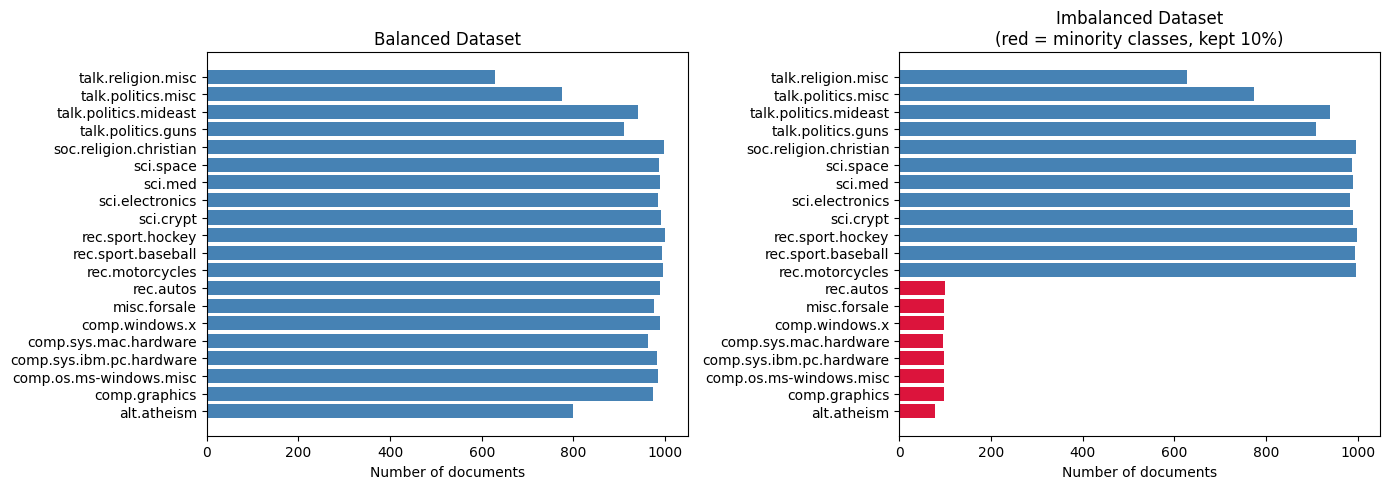

In [23]:
# ── Create imbalanced version ─────────────────────────────────────────────────
# Reduce 8 selected classes to 10% of their original size
minority_classes = [0, 1, 2, 3, 4, 5, 6, 7]   # first 8 classes become minority
keep_ratio       = 0.10

rng = np.random.default_rng(42)
keep_idx = []
for cls_id in range(K):
    idx_cls = np.where(labels_all == cls_id)[0]
    if cls_id in minority_classes:
        n_keep = max(1, int(len(idx_cls) * keep_ratio))
        keep_idx.extend(rng.choice(idx_cls, n_keep, replace=False).tolist())
    else:
        keep_idx.extend(idx_cls.tolist())

keep_idx = np.array(keep_idx)
texts_imb  = [texts[i]   for i in keep_idx]
labels_imb = labels_all[keep_idx]

print(f'Imbalanced dataset size: {len(texts_imb)}')
u2, c2 = np.unique(labels_imb, return_counts=True)

# Visualise imbalance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(cnames, counts, color='steelblue')
axes[0].set_title('Balanced Dataset')
axes[0].set_xlabel('Number of documents')
axes[1].barh(cnames, c2, color=['crimson' if i in minority_classes else 'steelblue'
                                  for i in range(K)])
axes[1].set_title('Imbalanced Dataset\n(red = minority classes, kept 10%)')
axes[1].set_xlabel('Number of documents')
plt.tight_layout()
plt.savefig(FIG / 'q3_class_distribution.png', dpi=200)
plt.show()

### 3d. Classify: Balanced Dataset

=== Balanced ===
[balanced]  sklearn acc=0.6976   scratch acc=0.4477


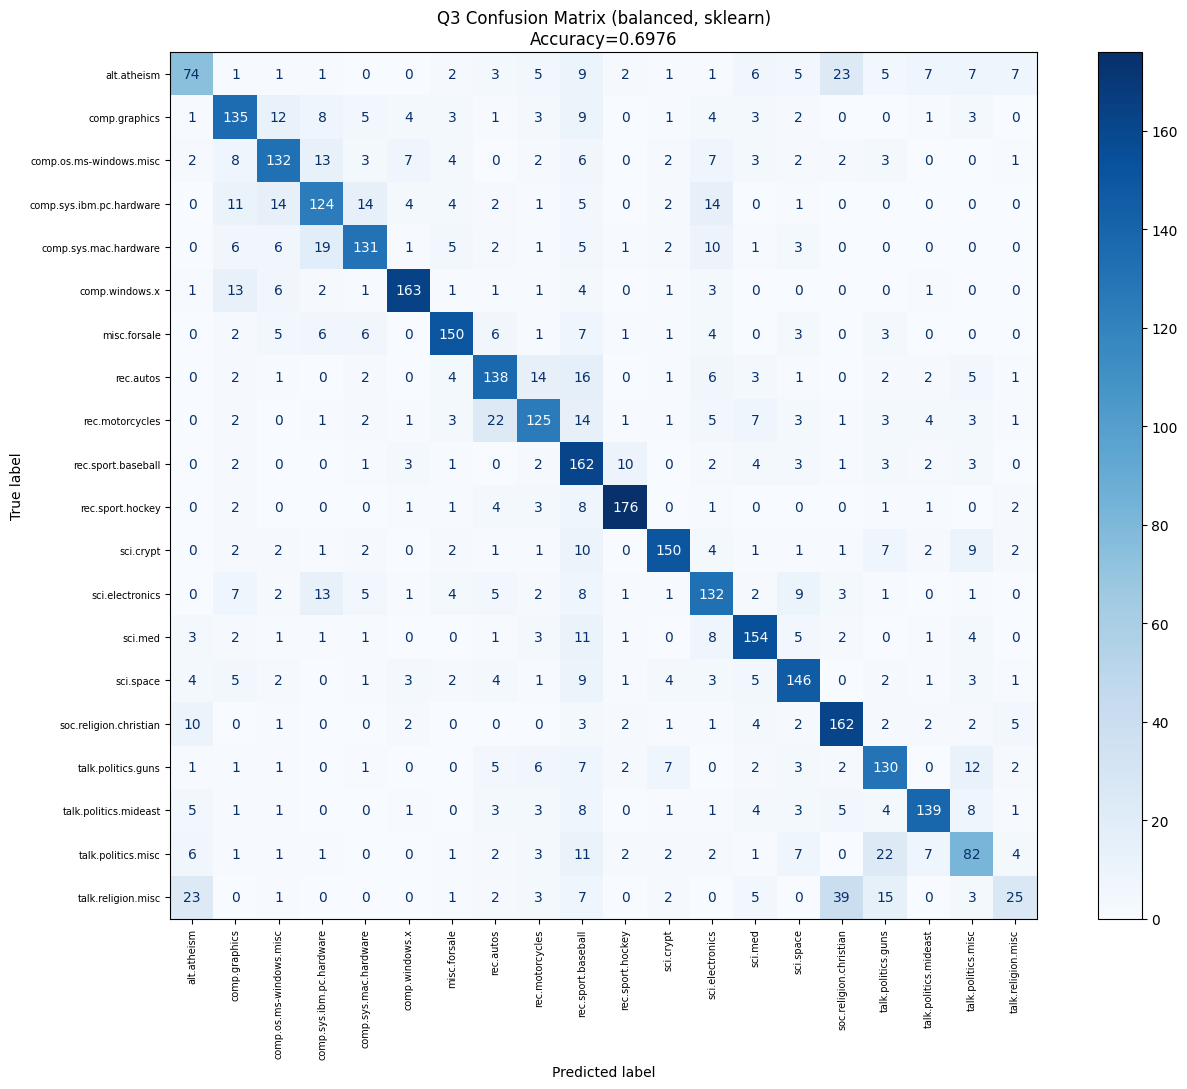

In [24]:
def run_newsgroups_experiment(texts_in, labels_in, tag='balanced'):
    """TF-IDF → sklearn LogReg + scratch softmax. Returns metrics dict."""
    Xtr_t, Xte_t, ytr, yte = train_test_split(
        texts_in, labels_in, test_size=0.2, random_state=42, stratify=labels_in)

    # TF-IDF
    vec  = TfidfVectorizer(max_features=5000, sublinear_tf=True)
    Xtr_tf = vec.fit_transform(Xtr_t).toarray()
    Xte_tf = vec.transform(Xte_t).toarray()

    # sklearn multinomial LogReg
    clf = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs',
                              multi_class='multinomial', random_state=42)
    clf.fit(Xtr_tf, ytr)
    y_lib = clf.predict(Xte_tf)

    acc_lib = accuracy_score(yte, y_lib)
    cm_lib  = confusion_matrix(yte, y_lib)

    # Scratch softmax
    K_local = len(np.unique(labels_in))
    Y_tr_oh = one_hot(ytr, K_local)
    W_s, losses_s = train_softmax_gd(Xtr_tf, Y_tr_oh, lr=0.5, max_iter=200, lam=1e-3)
    y_scratch     = predict_softmax(W_s, Xte_tf)
    acc_scratch   = accuracy_score(yte, y_scratch)
    cm_scratch    = confusion_matrix(yte, y_scratch)

    print(f'[{tag}]  sklearn acc={acc_lib:.4f}   scratch acc={acc_scratch:.4f}')

    # Plot confusion matrix (sklearn)
    fig, ax = plt.subplots(figsize=(14, 11))
    disp = ConfusionMatrixDisplay(cm_lib)
    disp.plot(ax=ax, colorbar=True, cmap='Blues',
              xticks_rotation='vertical')
    ax.set_xticklabels(cnames[:K_local], fontsize=7, rotation=90)
    ax.set_yticklabels(cnames[:K_local], fontsize=7)
    ax.set_title(f'Q3 Confusion Matrix ({tag}, sklearn)\nAccuracy={acc_lib:.4f}', fontsize=12)
    plt.tight_layout()
    plt.savefig(FIG / f'q3_cm_{tag}_sklearn.png', dpi=150)
    plt.show()

    return {
        'sklearn': {'acc': acc_lib,  'cm': cm_lib},
        'scratch': {'acc': acc_scratch, 'cm': cm_scratch},
        'losses_scratch': losses_s
    }


print('=== Balanced ===')
res_bal = run_newsgroups_experiment(list(texts), labels_all, tag='balanced')

### 3e. Classify: Imbalanced Dataset

=== Imbalanced ===
[imbalanced]  sklearn acc=0.7097   scratch acc=0.4166


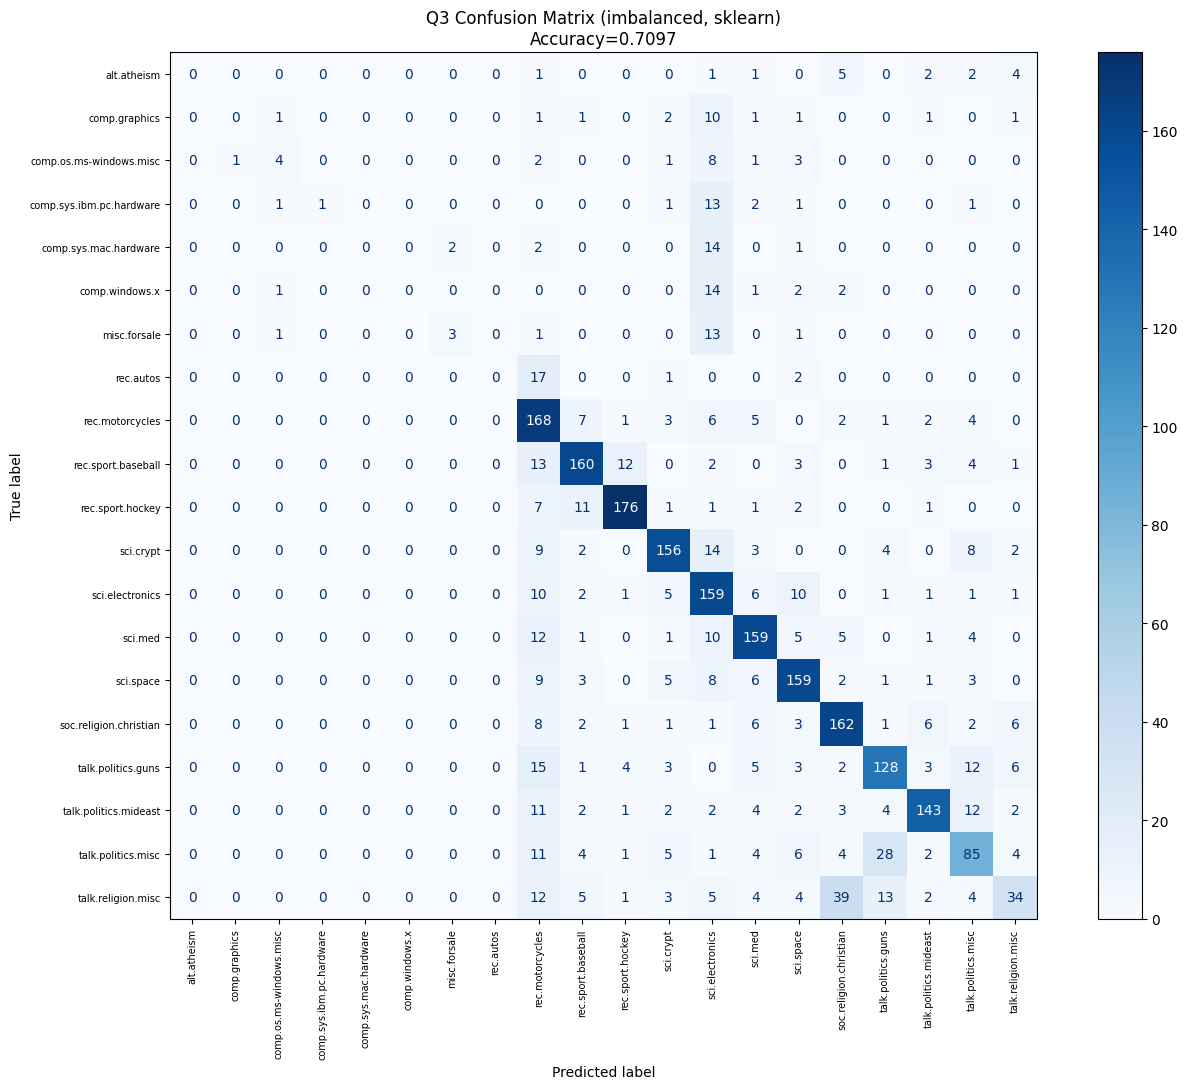

In [25]:
print('=== Imbalanced ===')
res_imb = run_newsgroups_experiment(texts_imb, labels_imb, tag='imbalanced')

### 3f. Comparison & Discussion


Accuracy Comparison:
  Balanced  — sklearn: 0.6976  |  scratch: 0.4477
  Imbalanced— sklearn: 0.7097  |  scratch: 0.4166

Discussion:
  On the balanced dataset the classifier performs well across all 20 classes.
  On the imbalanced dataset, overall accuracy can appear deceptively high because
  the model learns to favour majority classes. Minority classes (0–7, only 10%
  of original size) are systematically misclassified — visible as near-zero rows
  in the confusion matrix. This illustrates why overall accuracy is an inadequate
  metric for imbalanced problems; macro-averaged F1 or per-class recall are more
  informative. Mitigation strategies include oversampling (SMOTE), class-weight
  adjustment (class_weight='balanced'), or threshold tuning.



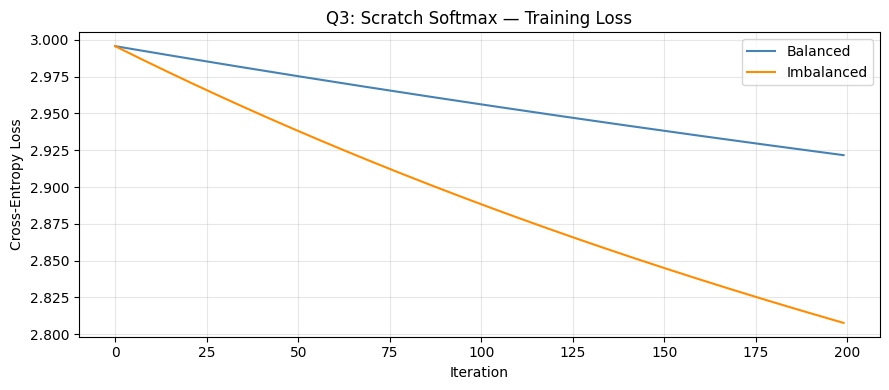

In [26]:
print(f"""\nAccuracy Comparison:
  Balanced  — sklearn: {res_bal['sklearn']['acc']:.4f}  |  scratch: {res_bal['scratch']['acc']:.4f}
  Imbalanced— sklearn: {res_imb['sklearn']['acc']:.4f}  |  scratch: {res_imb['scratch']['acc']:.4f}

Discussion:
  On the balanced dataset the classifier performs well across all 20 classes.
  On the imbalanced dataset, overall accuracy can appear deceptively high because
  the model learns to favour majority classes. Minority classes (0–7, only 10%
  of original size) are systematically misclassified — visible as near-zero rows
  in the confusion matrix. This illustrates why overall accuracy is an inadequate
  metric for imbalanced problems; macro-averaged F1 or per-class recall are more
  informative. Mitigation strategies include oversampling (SMOTE), class-weight
  adjustment (class_weight='balanced'), or threshold tuning.
""")

# Convergence of scratch softmax
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(res_bal['losses_scratch'], label='Balanced', color='steelblue')
ax.plot(res_imb['losses_scratch'], label='Imbalanced', color='darkorange')
ax.set_xlabel('Iteration')
ax.set_ylabel('Cross-Entropy Loss')
ax.set_title('Q3: Scratch Softmax — Training Loss')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q3_softmax_loss.png', dpi=200)
plt.show()

---
## Q4 — PCA on ORL Face Database

### 4a. Download & Load Dataset

In [27]:
import subprocess

# Download ORL faces if not already present
orl_zip = Path('att_faces.zip')
if not orl_zip.exists():
    print('Downloading ORL face database ...')
    subprocess.run(['wget', '-q',
                    'https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip'],
                   check=True)
    subprocess.run(['unzip', '-q', 'att_faces.zip'], check=True)
    print('Download complete.')
else:
    print('Dataset already downloaded.')

# ── Load images ────────────────────────────────────────────────────────────────
H, W = 112, 92   # ORL image dimensions
D    = H * W     # = 10304

data_dir    = Path('.')   # .pgm files extracted here
image_files = sorted(data_dir.rglob('*.pgm'))
print(f'Total .pgm images found: {len(image_files)}')
assert len(image_files) == 400, 'Expected 400 images (40 subjects × 10 each)'

imgs = []
for fp in image_files:
    arr = np.asarray(Image.open(fp), dtype=np.float64)
    imgs.append(arr.flatten())

X_faces = np.stack(imgs, axis=1)    # (10304, 400)
N       = X_faces.shape[1]
print(f'X_faces shape: {X_faces.shape}  (D={D}, N={N})')

Download complete.
Total .pgm images found: 400
X_faces shape: (10304, 400)  (D=10304, N=400)


### 4b. Display Sample Face Images

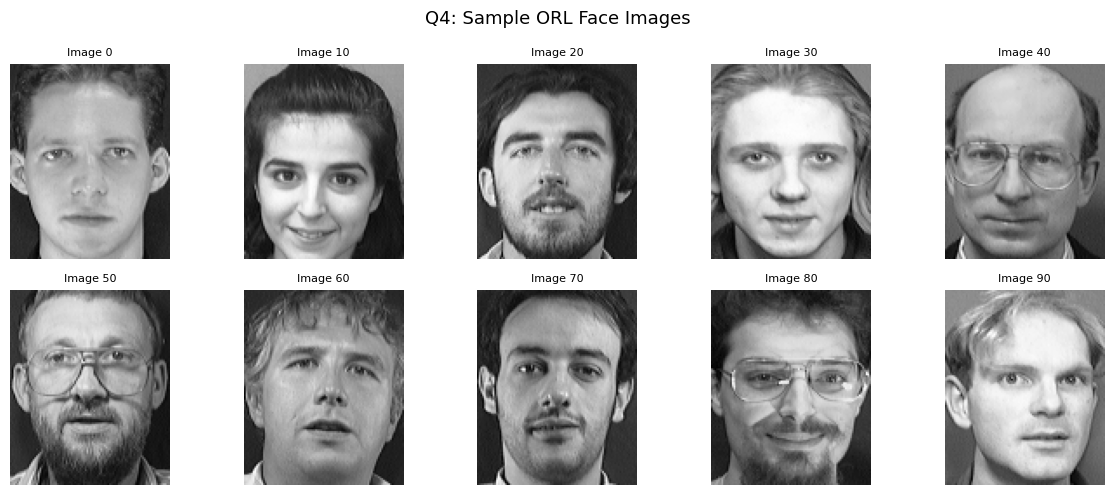

In [28]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
sample_idx = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(X_faces[:, idx].reshape(H, W), cmap='gray')
    ax.set_title(f'Image {idx}', fontsize=8)
    ax.axis('off')
plt.suptitle('Q4: Sample ORL Face Images', fontsize=13)
plt.tight_layout()
plt.savefig(FIG / 'q4_sample_faces.png', dpi=200)
plt.show()

### 4c. Mean Subtraction & Covariance Matrix

Mean face shape: (10304, 1)
Centred data Xc shape: (10304, 400)
Covariance S shape: (400, 400)


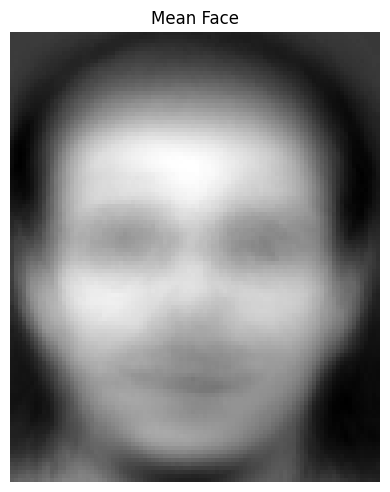

In [29]:
mean_face = np.mean(X_faces, axis=1, keepdims=True)   # (10304, 1)
Xc        = X_faces - mean_face                        # (10304, 400) centred

# Small covariance trick:  S = Xc^T Xc ∈ R^{400×400}
# (avoids computing the huge 10304×10304 matrix)
S = Xc.T @ Xc    # (400, 400)
print(f'Mean face shape: {mean_face.shape}')
print(f'Centred data Xc shape: {Xc.shape}')
print(f'Covariance S shape: {S.shape}')

# Visualise mean face
fig, ax = plt.subplots(figsize=(4, 5))
ax.imshow(mean_face.reshape(H, W), cmap='gray')
ax.set_title('Mean Face')
ax.axis('off')
plt.tight_layout()
plt.savefig(FIG / 'q4_mean_face.png', dpi=200)
plt.show()

### 4d. Eigendecomposition & Eigenfaces

In [30]:
# Eigendecomposition of small S (400×400)
eigvals, eigvecs = np.linalg.eigh(S)     # sorted ascending by eigh

# Sort descending
sort_idx = np.argsort(eigvals)[::-1]
eigvals  = eigvals[sort_idx]
eigvecs  = eigvecs[:, sort_idx]

# Recover eigenfaces of the full space: U = Xc @ V_small,  then normalise
U_raw = Xc @ eigvecs                                          # (10304, 400)
U     = U_raw / (np.linalg.norm(U_raw, axis=0, keepdims=True) + 1e-10)

print(f'Eigenfaces matrix U shape: {U.shape}')
print(f'Top-5 eigenvalues: {eigvals[:5]}')

Eigenfaces matrix U shape: (10304, 400)
Top-5 eigenvalues: [1.12674012e+09 8.25826045e+08 4.37721410e+08 3.56966463e+08
 3.26955753e+08]


### 4e. Visualise Eigenfaces for k = 1, 100, 200, 300, 400

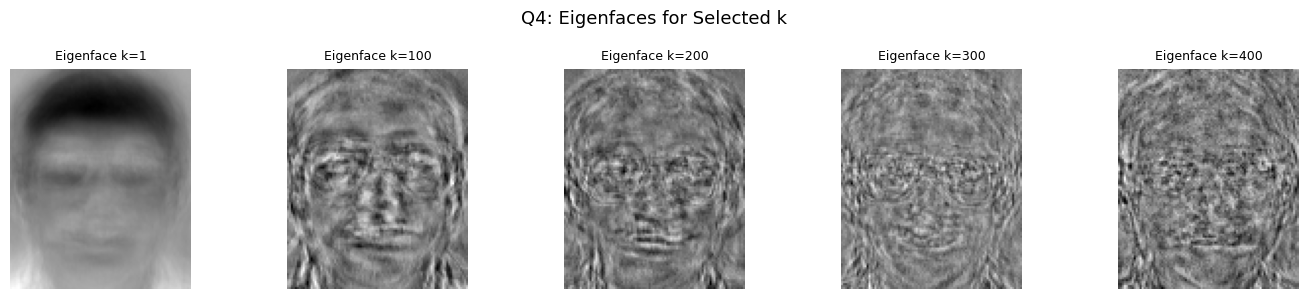

In [31]:
# k_list as per assignment: k = 1, 100, ..., D  (D=400)
k_vis = [1, 100, 200, 300, 400]

fig, axes = plt.subplots(1, len(k_vis), figsize=(14, 3))
for ax, k in zip(axes, k_vis):
    ef = U[:, k - 1].reshape(H, W)   # k-th eigenface (0-indexed)
    ax.imshow(ef, cmap='gray')
    ax.set_title(f'Eigenface k={k}', fontsize=9)
    ax.axis('off')
plt.suptitle('Q4: Eigenfaces for Selected k', fontsize=13)
plt.tight_layout()
plt.savefig(FIG / 'q4_eigenfaces.png', dpi=200)
plt.show()

### 4f. Variance Explained vs k

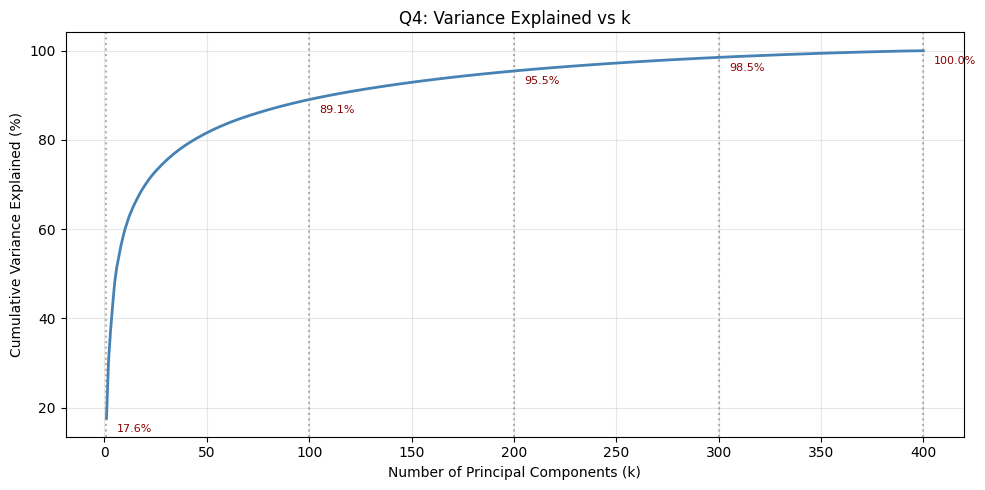

Variance explained at assignment k values:
  k=1   : 17.61%
  k=100 : 89.06%
  k=200 : 95.46%
  k=300 : 98.51%
  k=400 : 100.00%


In [32]:
# Variance explained
total_var   = np.sum(eigvals)
var_ratio   = np.cumsum(eigvals) / total_var   # cumulative explained variance

k_plot = list(range(1, N + 1))   # 1 … 400

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_plot, var_ratio * 100, color='steelblue', linewidth=2)

# Mark the assignment-specified k values
for k in k_vis:
    ax.axvline(k, color='gray', linestyle=':', alpha=0.6)
    ax.annotate(f'{var_ratio[k-1]*100:.1f}%', xy=(k, var_ratio[k-1]*100),
                xytext=(k+5, var_ratio[k-1]*100 - 3), fontsize=8, color='darkred')

ax.set_xlabel('Number of Principal Components (k)')
ax.set_ylabel('Cumulative Variance Explained (%)')
ax.set_title('Q4: Variance Explained vs k')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q4_variance_explained.png', dpi=200)
plt.show()

print('Variance explained at assignment k values:')
for k in k_vis:
    print(f'  k={k:<4}: {var_ratio[k-1]*100:.2f}%')

### 4g. PCA Projection, Reconstruction & Error (k = 1, 100, 200, 300, 400)

In [33]:
recon_errors = {}
var_lost     = {}
Xhat_dict    = {}

for k in k_vis:
    Uk        = U[:, :k]                    # (10304, k)
    V_k       = Uk.T @ Xc                   # (k, 400)  low-dim representation
    Xhat      = Uk @ V_k + mean_face        # (10304, 400) reconstructed
    err       = np.linalg.norm(X_faces - Xhat, 'fro')
    v_loss    = (1 - var_ratio[k - 1]) * 100
    recon_errors[k] = float(err)
    var_lost[k]     = float(v_loss)
    Xhat_dict[k]    = Xhat
    print(f'k={k:<4}: Frobenius error={err:12.3f}  variance lost={v_loss:.2f}%')

k=1   : Frobenius error=   72606.615  variance lost=82.39%
k=100 : Frobenius error=   26459.811  variance lost=10.94%
k=200 : Frobenius error=   17044.764  variance lost=4.54%
k=300 : Frobenius error=    9765.360  variance lost=1.49%
k=400 : Frobenius error=     262.143  variance lost=0.00%


### 4h. Reconstruction Error Plot

Computing full reconstruction error curve (k=1..400)...


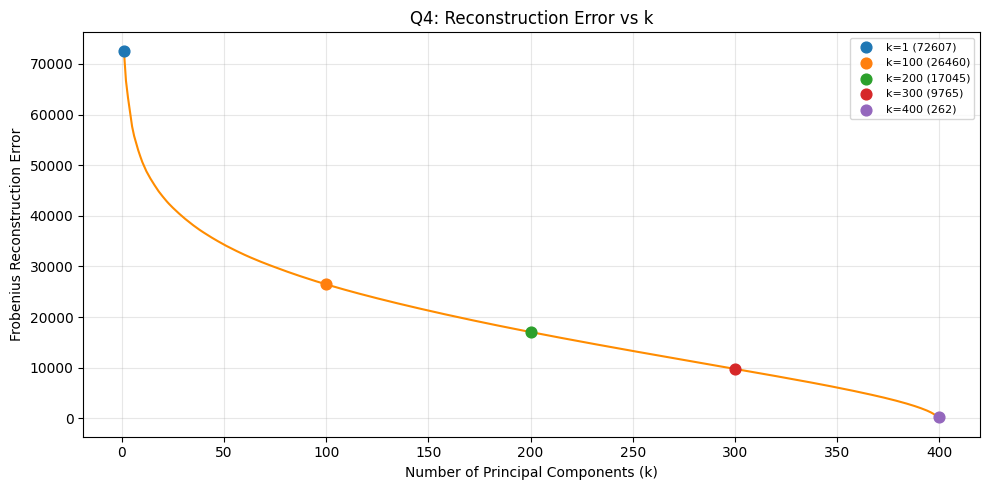

In [34]:
# Compute error for ALL k from 1 to N
errors_all = []
print('Computing full reconstruction error curve (k=1..400)...')
for k in range(1, N + 1):
    Uk   = U[:, :k]
    V_k  = Uk.T @ Xc
    Xhat = Uk @ V_k + mean_face
    errors_all.append(np.linalg.norm(X_faces - Xhat, 'fro'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, N + 1), errors_all, color='darkorange', linewidth=1.5)
for k in k_vis:
    ax.scatter(k, recon_errors[k], s=60, zorder=5,
               label=f'k={k} ({recon_errors[k]:.0f})')
ax.set_xlabel('Number of Principal Components (k)')
ax.set_ylabel('Frobenius Reconstruction Error')
ax.set_title('Q4: Reconstruction Error vs k')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / 'q4_reconstruction_error.png', dpi=200)
plt.show()

### 4i. Optimal k Selection

In [35]:
# Elbow / 95% variance criterion
k_95      = int(np.searchsorted(var_ratio, 0.95)) + 1
k_optimal = k_95

# Recompute reconstruction at k_optimal if not already in k_vis
Uk_opt  = U[:, :k_optimal]
V_opt   = Uk_opt.T @ Xc
Xhat_opt = Uk_opt @ V_opt + mean_face
err_opt  = np.linalg.norm(X_faces - Xhat_opt, 'fro')
var_exp  = var_ratio[k_optimal - 1] * 100

print(f"""Optimal k selection:
  Criterion      : First k that explains ≥ 95% cumulative variance
  Optimal k      : {k_optimal}
  Variance explained : {var_exp:.2f}%
  Variance lost      : {100 - var_exp:.2f}%
  Reconstruction error (Frobenius): {err_opt:.3f}
""")

Optimal k selection:
  Criterion      : First k that explains ≥ 95% cumulative variance
  Optimal k      : 190
  Variance explained : 95.02%
  Variance lost      : 4.98%
  Reconstruction error (Frobenius): 17841.639



### 4j. Visualise Original vs Reconstructed Faces

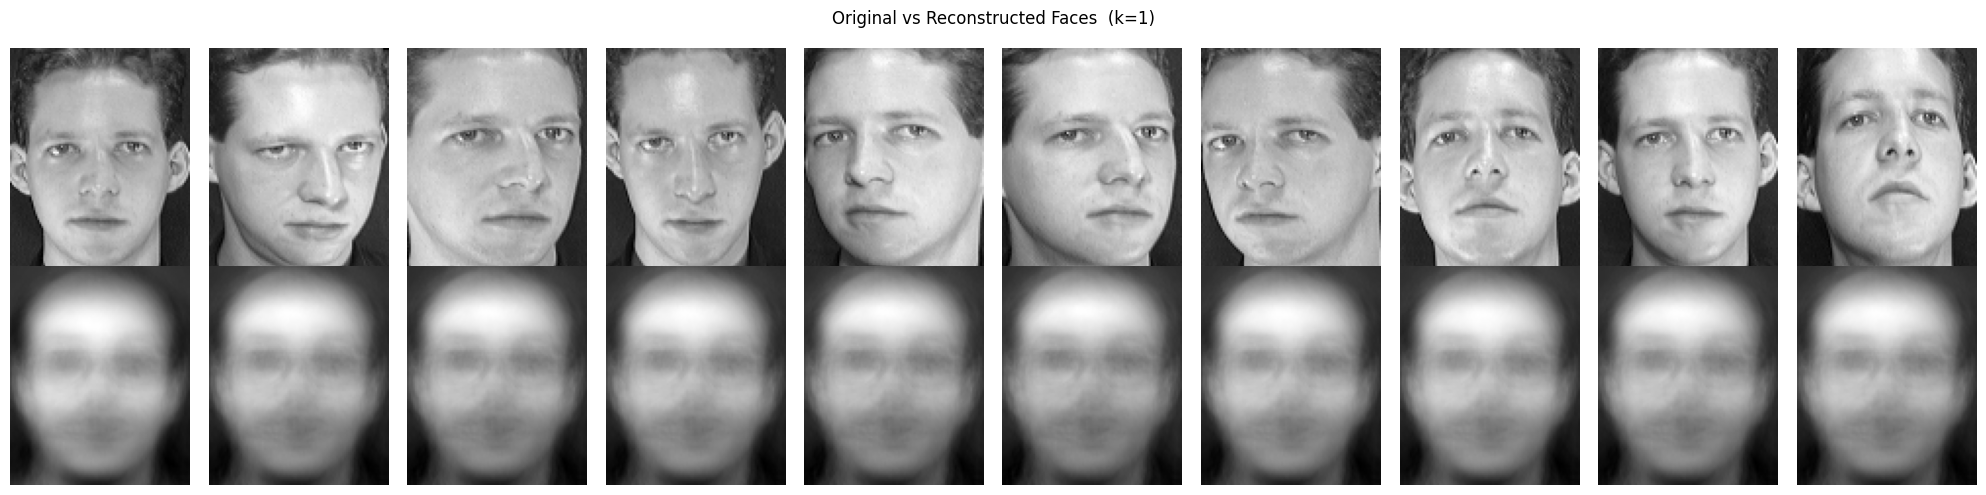

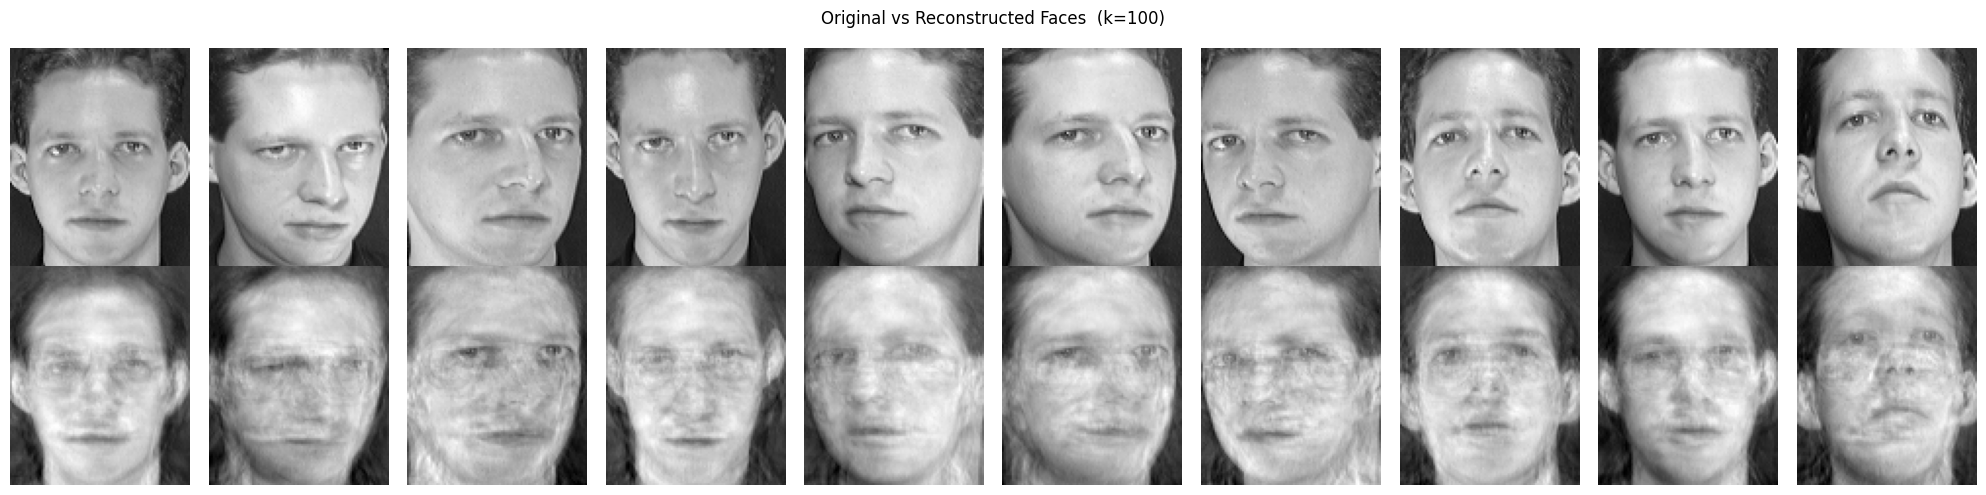

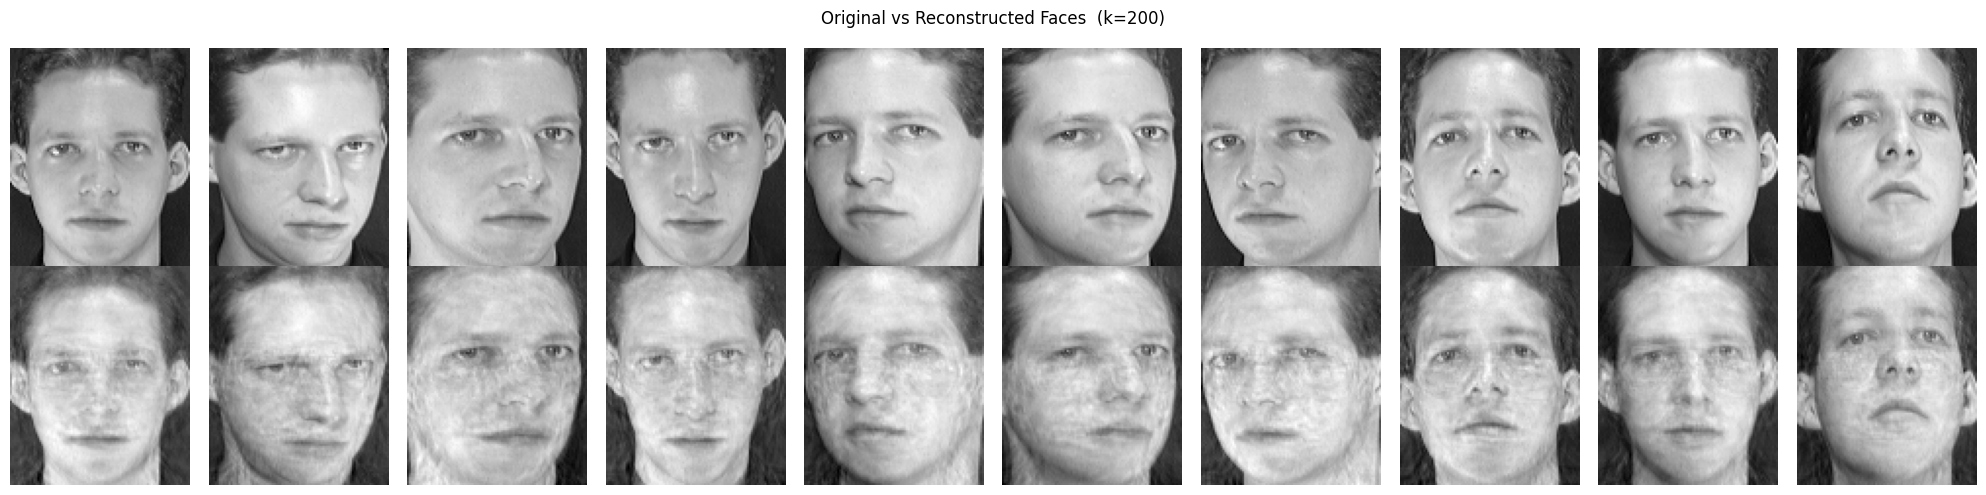

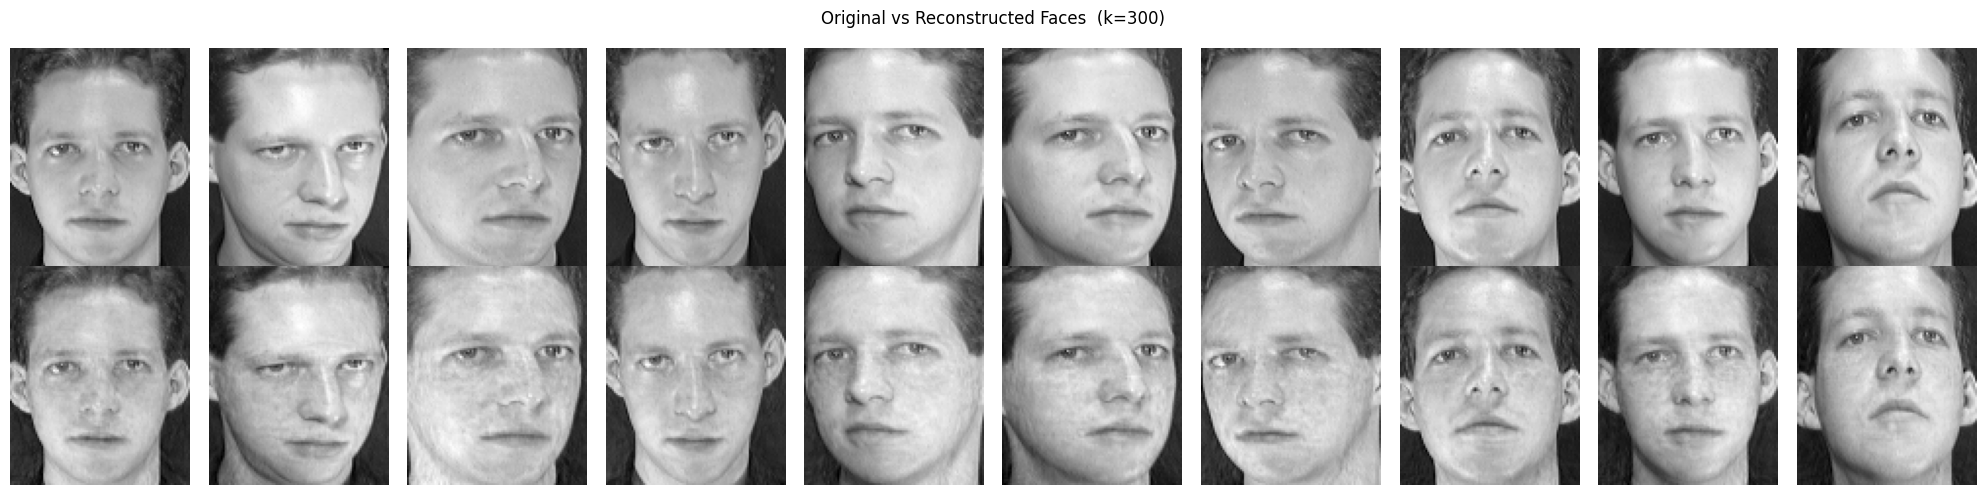

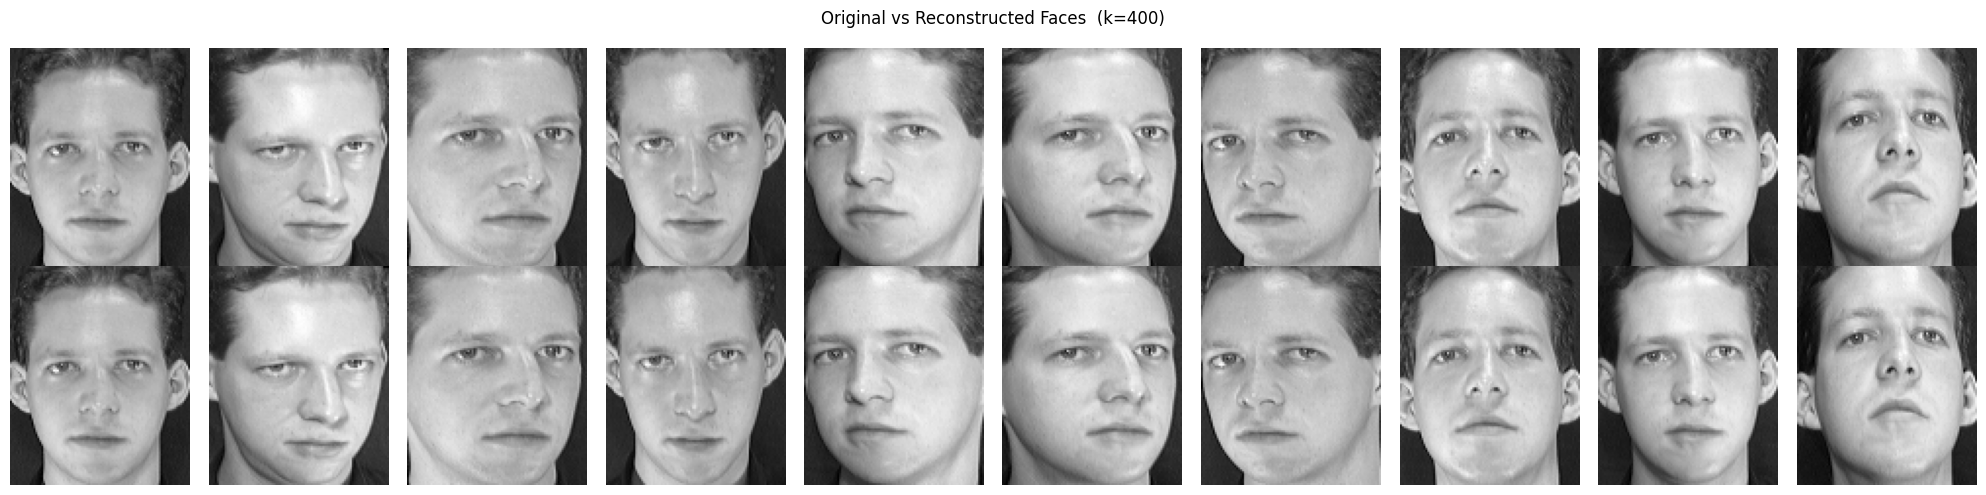


=== Optimal k=190 (95% variance) ===


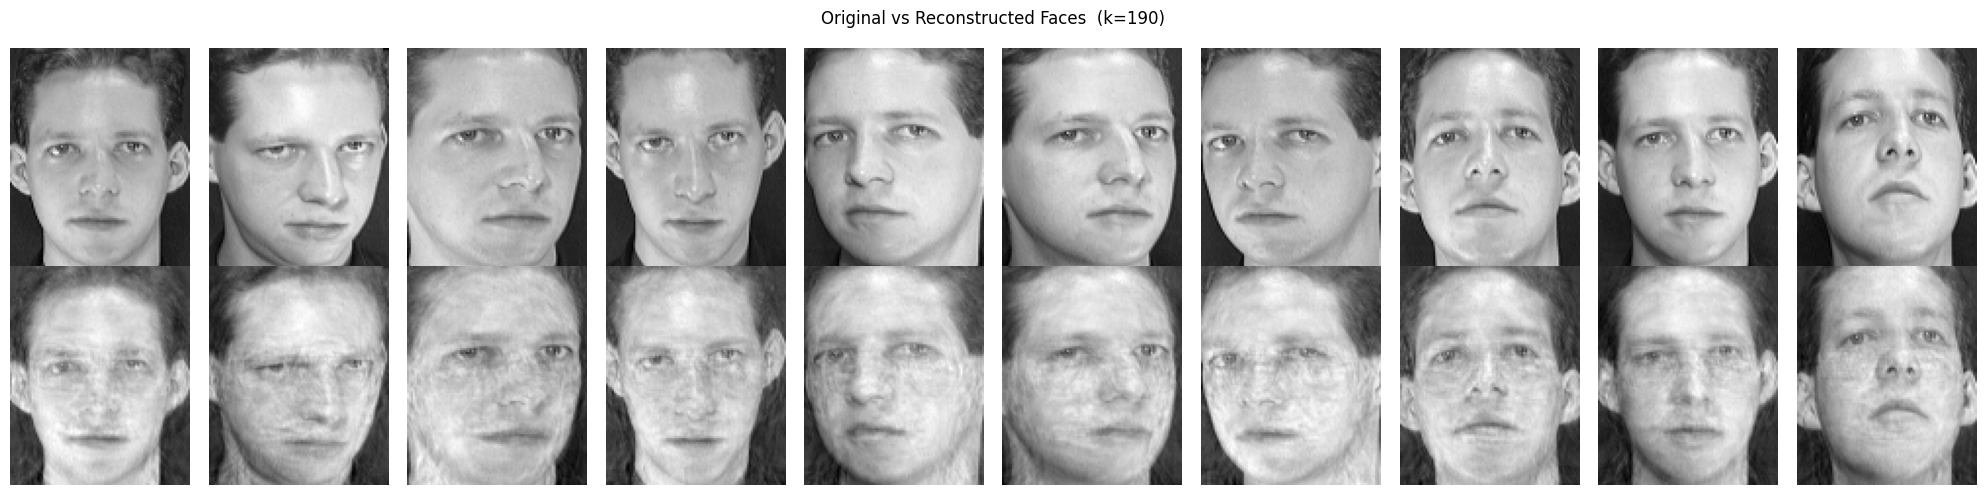

In [36]:
def plot_originals_vs_reconstructed(X_orig, Xhat, k_val, n_faces=10,
                                     fname=None):
    """Display n_faces pairs: original (top row) vs reconstructed (bottom row)."""
    fig, axes = plt.subplots(2, n_faces, figsize=(2 * n_faces, 5))
    for j in range(n_faces):
        axes[0, j].imshow(X_orig[:, j].reshape(H, W), cmap='gray')
        axes[0, j].axis('off')
        if j == 0:
            axes[0, j].set_ylabel('Original', fontsize=9)

        axes[1, j].imshow(Xhat[:, j].reshape(H, W), cmap='gray')
        axes[1, j].axis('off')
        if j == 0:
            axes[1, j].set_ylabel('Reconstructed', fontsize=9)

    plt.suptitle(f'Original vs Reconstructed Faces  (k={k_val})', fontsize=12)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=200)
    plt.show()


# --- Show for assignment k values ---
for k in k_vis:
    plot_originals_vs_reconstructed(X_faces, Xhat_dict[k], k_val=k,
                                    fname=FIG / f'q4_recon_k{k}.png')

# --- Show for optimal k ---
print(f'\n=== Optimal k={k_optimal} (95% variance) ===')
plot_originals_vs_reconstructed(X_faces, Xhat_opt, k_val=k_optimal,
                                fname=FIG / f'q4_recon_k_optimal.png')

### 4k. Summary

In [37]:
print('Q4 Summary:')
print(f'{"k":<6} {"Var Explained":>15} {"Var Lost":>10} {"Frob Error":>12}')
print('-' * 48)
for k in k_vis:
    ve = var_ratio[k-1]*100
    vl = 100 - ve
    print(f'{k:<6} {ve:>14.2f}% {vl:>9.2f}% {recon_errors[k]:>12.2f}')
print(f'\nOptimal k = {k_optimal}  (≥95% variance)')
print(f'  Variance explained : {var_exp:.2f}%')
print(f'  Variance lost      : {100-var_exp:.2f}%')
print(f'  Frobenius error    : {err_opt:.3f}')
print("""
Interpretation:
  At k=1 the reconstruction is a blurry average face with huge error.
  As k increases, faces become progressively sharper and more identifiable.
  At the optimal k (≥95% variance) the reconstructed faces are visually
  very close to the originals while achieving substantial dimensionality
  reduction (from D=10304 to k dimensions).
  Beyond ~200 components the marginal reduction in error is small,
  confirming diminishing returns.
""")

Q4 Summary:
k        Var Explained   Var Lost   Frob Error
------------------------------------------------
1               17.61%     82.39%     72606.62
100             89.06%     10.94%     26459.81
200             95.46%      4.54%     17044.76
300             98.51%      1.49%      9765.36
400            100.00%      0.00%       262.14

Optimal k = 190  (≥95% variance)
  Variance explained : 95.02%
  Variance lost      : 4.98%
  Frobenius error    : 17841.639

Interpretation:
  At k=1 the reconstruction is a blurry average face with huge error.
  As k increases, faces become progressively sharper and more identifiable.
  At the optimal k (≥95% variance) the reconstructed faces are visually
  very close to the originals while achieving substantial dimensionality
  reduction (from D=10304 to k dimensions).
  Beyond ~200 components the marginal reduction in error is small,
  confirming diminishing returns.



In [40]:
# ── Download all output files individually (Google Colab) ─────────────────────
import os
from pathlib import Path
from google.colab import files

# 1. All figures
if Path('figures').exists():
    for f in sorted(Path('figures').glob('*.png')):
        print(f'⬇️  Downloading {f.name} ...')
        files.download(str(f))

    # 2. Any loose .png files in root
    for f in sorted(Path('.').glob('*.png')):
        print(f'⬇️  Downloading {f.name} ...')
        files.download(str(f))

    # 3. Any .csv, .json, .npy, .pkl files
    for ext in ['*.csv', '*.json', '*.npy', '*.pkl']:
        for f in sorted(Path('.').glob(ext)):
            print(f'⬇️  Downloading {f.name} ...')
            files.download(str(f))

print('\n✅ All files downloaded!')

⬇️  Downloading q1_3d_scatter.png ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Downloading q1_boundary_Age_EstimatedSalary.png ...


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

⬇️  Downloading stats_females - stats_females.csv ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ All files downloaded!


In [41]:
# ── Download all outputs (Google Colab) ───────────────────────────────────────
import shutil, os
from pathlib import Path
from google.colab import files

# ── Step 1: Zip the figures folder ────────────────────────────────────────────
if Path('figures').exists():
    shutil.make_archive('figures_output', 'zip', 'figures')
    print(f"✅ figures_output.zip  ({os.path.getsize('figures_output.zip')/1024:.1f} KB)")
else:
    print("⚠️  'figures/' folder not found — skipping")

# ── Step 2: Zip the ORL face folders (s1..s40) ────────────────────────────────
face_dirs = sorted(Path('.').glob('s[0-9]*'))
if face_dirs:
    tmp_faces = Path('_tmp_faces')
    tmp_faces.mkdir(exist_ok=True)
    for d in face_dirs:
        shutil.copytree(d, tmp_faces / d.name, dirs_exist_ok=True)
    shutil.make_archive('orl_faces_output', 'zip', str(tmp_faces))
    shutil.rmtree(tmp_faces)
    print(f"✅ orl_faces_output.zip  ({os.path.getsize('orl_faces_output.zip')/1024:.1f} KB)")
else:
    print("ℹ️  No ORL face folders found — skipping")

# ── Step 3: Collect loose files in working directory ──────────────────────────
loose_patterns = ['*.png', '*.csv', '*.json', '*.txt', '*.npy', '*.pkl']
loose_files    = []
for pat in loose_patterns:
    loose_files.extend([f for f in Path('.').glob(pat)
                        if not f.name.endswith('_output.zip')])

if loose_files:
    tmp_loose = Path('_tmp_loose')
    tmp_loose.mkdir(exist_ok=True)
    for f in loose_files:
        shutil.copy(f, tmp_loose / f.name)
    shutil.make_archive('loose_files_output', 'zip', str(tmp_loose))
    shutil.rmtree(tmp_loose)
    print(f"✅ loose_files_output.zip  ({os.path.getsize('loose_files_output.zip')/1024:.1f} KB)")
    print(f"   Files included: {[f.name for f in loose_files]}")
else:
    print("ℹ️  No loose files found — skipping")

# ── Step 4: Bundle everything into one master zip ─────────────────────────────
tmp_master = Path('_tmp_master')
tmp_master.mkdir(exist_ok=True)

for z in Path('.').glob('*_output.zip'):
    shutil.copy(z, tmp_master / z.name)

shutil.make_archive('ML_Assignment2_ALL_outputs', 'zip', str(tmp_master))
shutil.rmtree(tmp_master)

size_mb = os.path.getsize('ML_Assignment2_ALL_outputs.zip') / (1024 * 1024)
print(f"\n📦 Master zip ready: ML_Assignment2_ALL_outputs.zip  ({size_mb:.2f} MB)")

# ── Step 5: Download to your computer ─────────────────────────────────────────
print("\n⬇️  Starting download ...")
files.download('ML_Assignment2_ALL_outputs.zip')
print("✅ Done!")

✅ figures_output.zip  (5323.2 KB)
✅ orl_faces_output.zip  (3679.8 KB)
✅ loose_files_output.zip  (1.1 KB)
   Files included: ['salary_data - salary_data.csv', 'stats_females - stats_females.csv']

📦 Master zip ready: ML_Assignment2_ALL_outputs.zip  (8.78 MB)

⬇️  Starting download ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Done!
